# 17 · Kümeleme - Hiyerarşik ve Yoğunluk Tabanlı Yöntemler (Clustering: Hierarchical & Density-Based Methods)

> **Bu notebook'ta ne öğreneceğiz?**
> 16 · Bölümleme Yöntemleri'nde K-Means'in iki büyük sınırlamasını gördük: (1) **$k$'yı
> önceden söylemek zorundayız**, (2) kümelerin **yuvarlak/küresel** olduğunu varsayıyor
> (ay şeklindeki veride ARI≈0 çıkmıştı). Bu notebook bu iki sorunu çözen üç yöntem ailesini
> anlatıyor — her birini önce **küçük, elle hesaplanabilir bir örnekle**, sonra gerçek
> veriyle öğreneceğiz:
>
> 1. **Hiyerarşik (Agglomerative) kümeleme:** "En yakın iki grubu birleştir" kuralını tekrar
>    tekrar uygulayıp bir **ağaç (dendrogram)** üretir; $k$'yı sonradan, ağacı keserek seçeriz.
>    Dört bağlantı (linkage) türü: single, complete, average, Ward.
> 2. **DBSCAN (yoğunluk tabanlı):** Kümeyi "yoğun bir bölge" olarak tanımlar; küme sayısını
>    kendisi bulur, **gürültü noktalarını** ayrıca etiketler, her şekildeki kümeyi yakalar.
>    Ek olarak OPTICS ve HDBSCAN'e kısa bakış.
> 3. **Gaussian Mixture Model (GMM):** "Her nokta *kesin olarak* tek bir kümeye ait" yerine
>    "bu noktanın %70 A'ya, %30 B'ye ait olma ihtimali var" diyen **yumuşak (soft)**
>    kümeleme. Küme sayısını BIC ile seçeriz.
>
> Üç yöntemin de çekirdek mantığını **sıfırdan** kodlayıp scikit-learn / SciPy ile
> doğrulayacağız.
>
> **Önkoşul:** 16 · Kümeleme - Bölümleme Yöntemleri (K-Means, Silhouette), 01 · Veri Ön İşleme
> (ölçekleme).
>
> **Veri:** `USArrests` (50 ABD eyaleti, suç oranları — hiyerarşik kümeleme için klasik ve
> dendrogramı okunabilir boyutta), `quakes` (Fiji bölgesi 1000 deprem, enlem/boylam — DBSCAN
> için doğal coğrafi veri), `faithful` (Old Faithful gayzeri, 272 patlama — GMM için iki
> belirgin gruplu klasik veri) ve şekil karşılaştırması için sentetik veriler. Üçü de
> serinin önceki notebook'larında **kullanılmamış** veri setleri.
>
> **Araçlar:** `scipy.cluster.hierarchy`, `sklearn.cluster` (`AgglomerativeClustering`,
> `DBSCAN`, `OPTICS`, `HDBSCAN`), `sklearn.mixture.GaussianMixture`, R (`hclust`, `mclust`),
> DuckDB (SQL).

## 1 · Neden K-Means Yetmedi? Üç Farklı Cevap

16'da K-Means'i bir **kalıp (şablon) yerleştirme** işi gibi düşünebiliriz: "$k$ tane yuvarlak
balon koy, her noktayı en yakın balonun merkezine ata." Bu şablon üç durumda bozulur:

| K-Means'in sorunu | Somut örnek | Hangi yöntem çözüyor? |
|---|---|---|
| $k$'yı baştan bilmek gerek | "Müşterileri kaç gruba ayırmalıyım?" sorusunun cevabı yok | **Hiyerarşik:** tüm $k$'ları tek ağaçta verir, sonradan kesilir |
| Küme şekli yuvarlak olmak zorunda | Deprem odakları bir **fay hattı boyunca uzanan** şerit gibidir, yuvarlak değil | **DBSCAN:** şekil varsaymaz, "yoğunluk" arar |
| Her nokta bir kümeye *zorla* atanır | İki grubun ortasındaki bir nokta ya A ya B olur, "emin değilim" diyemez | **GMM:** her noktaya olasılık verir (%40 A, %60 B) |

Ek bir sorun: K-Means **aykırı değerleri de bir kümeye zorla koyar** (16'da Wholesale verisinde
5 kişilik "hayalet" kümeyi hatırlayın). DBSCAN bunlara açıkça **"gürültü (noise)"** etiketi
verebilir.

Bu üç yöntem rakip değil, **farklı sorulara cevap verir**:
- "Verimin hiyerarşik bir yapısı var mı, alt-gruplar iç içe mi?" → Hiyerarşik
- "Verimde yoğun bölgeler ve bunların dışında dağınık/anormal noktalar mı var?" → DBSCAN
- "Gruplar birbirine karışıyor ve ben 'ne kadar emin olduğumu' da bilmek istiyorum" → GMM

## 2 · Hiyerarşik (Agglomerative) Kümeleme: "En Yakın İki Grubu Birleştir"

### 2.1 Algoritma (çok basit)

1. Başlangıçta **her nokta tek başına bir küme** ($n$ küme).
2. Birbirine **en yakın iki kümeyi** bul ve **birleştir** ($n-1$ küme kalır).
3. Tek küme kalana kadar 2'yi tekrarla.

Bu sürecin kaydı bir **ağaçtır (dendrogram)**. Ağacı yatay bir çizgiyle keseriz: çizgi ne kadar
yüksekteyse o kadar az (ama daha kaba) küme elde ederiz. Yani $k$'yı **sonradan** seçeriz.

**Aklınızda bir benzetme:** Bir okulda sıra arkadaşları, sonra masa grupları, sonra sınıflar,
sonra sınıf seviyeleri... şeklinde "iç içe geçmiş" gruplamalar. Hiyerarşik kümeleme bu
kademeli birleşmeyi veriden otomatik çıkarır.

### 2.2 Tek soru: "İki *küme* arasındaki uzaklık nedir?"

İki nokta arasındaki uzaklığı biliyoruz (Öklid). Ama iki **grup** arasında? Burada "linkage"
(bağlantı) kuralı devreye girer — farklı kurallar farklı kümeleme sonuçları verir:

| Linkage | İki küme $A$, $B$ arası uzaklık | Sezgi (günlük hayat benzetmesi) |
|---|---|---|
| **Single** | $\min_{a\in A, b\in B} d(a,b)$ | "En yakın **iki kişi** arasındaki mesafe" — iki köyün en yakın evleri arası. Zincirleme birleşir. |
| **Complete** | $\max_{a\in A, b\in B} d(a,b)$ | "En **uzak** iki kişi arasındaki mesafe" — iki köyün en uç evleri arası. Sıkı, kompakt kümeler. |
| **Average** | $\frac{1}{\lvert A\rvert\lvert B\rvert}\sum_{a,b} d(a,b)$ | "Tüm çiftlerin **ortalama** mesafesi" — ikisinin arası bir uzlaşma. |
| **Ward** | Birleşmenin küme-içi kareler toplamını (SSE) **ne kadar artıracağı** | "Birleşince grup ne kadar **dağılır**?" — K-Means'in amaç fonksiyonuyla aynı mantık. |

### 2.3 🔍 Somut örnek: 5 noktayı elle birleştirelim

Tek boyutlu 5 nokta düşünelim: $A=1,\; B=2,\; C=6,\; D=8,\; E=15$ (bir doğru üzerinde).
İkili uzaklıklar $d(x,y)=|x-y|$:

| | A(1) | B(2) | C(6) | D(8) | E(15) |
|---|---|---|---|---|---|
| **A** | 0 | 1 | 5 | 7 | 14 |
| **B** | | 0 | 4 | 6 | 13 |
| **C** | | | 0 | 2 | 9 |
| **D** | | | | 0 | 7 |

En küçük uzaklık $d(A,B)=1$ → ilk birleşme $\{A,B\}$. Sonra $d(C,D)=2$ → $\{C,D\}$.
Üçüncü adımda üç aday var: $\{A,B\}$–$\{C,D\}$, $\{C,D\}$–$E$, $\{A,B\}$–$E$.
**Linkage kuralına göre hesap değişir:**

- **Single:** $\{A,B\}$–$\{C,D\}$ = $\min(5,7,4,6) = 4$; $\{C,D\}$–$E$ = $\min(9,7) = 7$ → önce **4'te**
  $\{A,B,C,D\}$ oluşur, sonra $E$ **7'de** katılır (çünkü $D$–$E$ = 7: zincirin son halkası).
- **Complete:** $\{A,B\}$–$\{C,D\}$ = $\max(5,7,4,6) = 7$; $\{C,D\}$–$E$ = $\max(9,7)=9$ → **7'de** dörtlü
  oluşur, sonra $E$ **14'te** katılır (en uzak çift $A$–$E$ = 14).
- **Average:** $\{A,B\}$–$\{C,D\}$ = $(5+7+4+6)/4 = 5.5$; $\{C,D\}$–$E$ = $(9+7)/2 = 8$ → **5.5'te** dörtlü, sonra
  $E$ **10.75'te** ($=(14+13+9+7)/4$).
- **Ward:** İki grubun birleşmesinin SSE'ye eklediği artış $\Delta = \frac{n_A n_B}{n_A+n_B}\,\lVert\bar x_A-\bar x_B\rVert^2$.
  $\{A,B\}$ merkezi 1.5, $\{C,D\}$ merkezi 7 → $\Delta=\frac{2\cdot2}{4}(5.5)^2=30.25$; $E$ ile $\{C,D\}$
  için $\Delta = \frac{2\cdot 1}{3}(15-7)^2 = 42.67$ → önce $\{A,B,C,D\}$ ($30.25$), sonra $E$
  ($\Delta=\frac{4\cdot1}{5}(15-4.25)^2 = 92.45$).

**Ders:** Aynı 5 noktada **single** $E$'yi "nispeten yakın" gösterir (7), **complete** ise "çok uzak"
(14). Single linkage'in bu "en yakın komşuya bakıp karar verme" huyu, birbirinden aslında ayrı
iki kümeyi **ince bir nokta köprüsüyle** birleştirebilir — buna **zincirleme etkisi (chaining)** denir.
Bu örneği Python'da Adım 2'de kodla doğrulayacağız.

### 2.4 Dendrogram nasıl okunur?

- **Yatay eksen:** noktalar (yaprak = tek bir gözlem). **Dikey eksen:** birleşmenin gerçekleştiği
  uzaklık ("yükseklik").
- İki dal ne kadar **alçakta** birleşiyorsa o iki grup birbirine o kadar **benzer**.
- **Kesme çizgisi:** yatay çizgiyi bir yüksekliğe çekin; çizginin kestiği dal sayısı = küme sayısı.
  **Pratik kural:** birleşme yüksekliklerinde **büyük bir sıçrama** (uzun dikey bir "boşluk")
  varsa, çizgiyi o boşluğun içinden geçirin — "bu iki birleşme arasında kümeler gerçekten
  birbirinden ayrık" demektir.
- ⚠️ **Sık yapılan hata:** Dendrogramda yatay sıra (soldan sağa) **anlamsızdır**; iki dal yer
  değiştirebilir. Sadece **hangi yükseklikte birleştikleri** anlamlıdır.

### 2.5 Kalite ölçüsü: Kofenetik Korelasyon (Cophenetic Correlation)

Dendrogram, aslında verideki tüm ikili uzaklıkları **basitleştirilmiş** (ağaç mesafesi olarak)
saklar: iki noktanın "kofenetik uzaklığı", onların ağaçta **ilk birleştikleri yüksekliktir**.
Kofenetik korelasyon, bu basitleştirilmiş uzaklıklarla **gerçek** uzaklıkların korelasyonudur
(1'e yakın = ağaç, verinin gerçek uzaklık yapısını iyi koruyor).

### 2.6 Karmaşıklık ve sınırlar

Tüm ikili uzaklıkları saklamak gerekir: bellek $O(n^2)$, zaman en az $O(n^2)$ ($O(n^3)$'e kadar
çıkabilir naif uygulamada). **~10-20 bin örneğin üzerinde pratik değildir.** Ayrıca bir kez
yapılan birleşme **geri alınamaz** (açgözlü). Bu yüzden büyük veride K-Means / Mini-Batch daha
uygundur.

**Endüstride nerede kullanılır?**
- **Biyoinformatik:** gen ifade verisinde (mikrodizi / RNA-seq) benzer şekilde davranan genleri ve
  hastaları gruplamak; filogenetik ağaçlar (türlerin akrabalık ağacı) aslında bir hiyerarşik
  kümelemedir.
- **Doküman/haber organizasyonu:** haberleri konu ağacına (Spor → Futbol → Süper Lig) dizmek.
- **Pazarlama:** ürün taksonomisi (kategori → alt kategori) çıkarmak, müşteri segmentlerinin
  "ana grup → alt grup" yapısını görmek.

## 3 · DBSCAN: "Kümeyi Yoğun Bir Bölge Olarak Tanımla"

### 3.1 Sezgi: Kalabalık ve boş meydan benzetmesi

Bir şehir haritasına **kuşbakışı** bakıp insanları nokta olarak çizdiğinizi düşünün. Meydanlar,
konser alanları kalabalık (yoğun) bölgelerdir; aralarındaki yollar ve boş araziler ise
seyrektir. **Küme = kalabalık bir bölge**; kalabalıktan uzakta tek başına duran birkaç kişi
= **gürültü**. DBSCAN (Ester ve ark., 1996) bu fikri formülleştirir — **$k$'yı söylemeniz
gerekmez**, kalabalıkların sayısını ve şeklini kendisi bulur.

### 3.2 İki parametre

- $\varepsilon$ (`eps`): "komşuluk yarıçapı" — bir noktanın etrafına çizilen dairenin yarıçapı.
- `minPts` (`min_samples`): "bir bölgenin *kalabalık* sayılması için gereken en az nokta sayısı"
  (noktanın kendisi dahil).

Bir $p$ noktasının $\varepsilon$-komşuluğu: $N_\varepsilon(p)=\{q : d(p,q)\le\varepsilon\}$.

### 3.3 Üç tür nokta

| Tür | Kural | Benzetme |
|---|---|---|
| **Çekirdek (core) nokta** | $\lvert N_\varepsilon(p)\rvert \ge \text{minPts}$ | Kalabalığın **tam ortasındaki** kişi: etrafında yeterince insan var |
| **Sınır (border) nokta** | Çekirdek değil ama bir çekirdeğin $\varepsilon$-komşuluğunda | Kalabalığın **kıyısındaki** kişi: kendi etrafı seyrek ama kalabalığın kenarında |
| **Gürültü (noise)** | Ne çekirdek ne sınır | Kalabalıktan **uzakta** tek başına duran kişi |

**Küme oluşturma:** Birbirinin $\varepsilon$-komşuluğunda olan çekirdek noktalar **zincirleme**
birleşir (bir çekirdekten komşu çekirdeğe "yürüyerek" ulaşılan her şey aynı kümedir); sınır
noktalar komşu oldukları çekirdeğin kümesine katılır; gürültüler etiketsiz kalır (`-1`).

### 3.4 🔍 Somut örnek: bir doğru üzerinde 9 nokta

Noktalar: $1.0,\;1.2,\;1.4,\;1.9,\;2.9,\;5.0,\;5.1,\;5.2,\;8.0$. Parametreler: $\varepsilon=0.55$,
$\text{minPts}=3$. Her noktanın $\varepsilon$ içindeki komşu sayısı (kendisi dahil):

| Nokta | Komşuları ($\lvert x-p\rvert\le0.55$) | Sayı | Tür |
|---|---|---|---|
| 1.0 | 1.0, 1.2, 1.4 | 3 | **çekirdek** |
| 1.2 | 1.0, 1.2, 1.4 | 3 | **çekirdek** |
| 1.4 | 1.0, 1.2, 1.4, 1.9 | 4 | **çekirdek** |
| 1.9 | 1.4, 1.9 | 2 | **sınır** (çekirdek 1.4'ün komşusu) |
| 2.9 | 2.9 | 1 | **gürültü** |
| 5.0 / 5.1 / 5.2 | birbirleri | 3'er | **çekirdek** (ikinci küme) |
| 8.0 | 8.0 | 1 | **gürültü** |

Sonuç: **2 küme** ($\{1.0,1.2,1.4,1.9\}$ ve $\{5.0,5.1,5.2\}$) ve **2 gürültü** noktası
($2.9$, $8.0$). Dikkat: $1.9$ kendisi kalabalık değil, ama kalabalığın kenarında olduğu için
kümeye **dahil**; $2.9$ ise hiçbir çekirdeğe yeterince yakın değil → **dışarıda**. Bu örneği
Adım 7'de kodla birebir yeniden üreteceğiz.

### 3.5 $\varepsilon$ nasıl seçilir? — $k$-uzaklık grafiği

Her nokta için **$k$-ıncı en yakın komşusuna uzaklığı** hesapla ($k=\text{minPts}$), bu
uzaklıkları **küçükten büyüğe sırala** ve çiz. Eğrinin **dirsek (knee)** yaptığı yer iyi bir
$\varepsilon$ adayıdır. **Neden?** Küme içindeki noktaların $k$-komşu uzaklığı küçüktür
(yoğun bölge); gürültü noktalarınki aniden büyüktür. Eğrinin düz kısmından dik kısmına geçtiği
nokta tam olarak "yoğun" ile "seyrek" arasındaki sınırdır.

### 3.6 DBSCAN'in güçlü ve zayıf yanları

**Güçlü:** (1) $k$ gerekmez, (2) **keyfi şekilli** kümeler (hilal, halka, şerit), (3) gürültüyü
açıkça ayırır (aykırı değer tespiti de yapar), (4) ε-sorgusu indeksle hızlandırılırsa
$O(n\log n)$.

**Zayıf:** (1) **Tek bir $\varepsilon$** tüm kümeler için geçerli → **farklı yoğunluktaki**
kümelerde ya yoğun küme parçalanır ya da seyrek küme gürültü sayılır, (2) yüksek boyutta
uzaklıklar anlamsızlaşır (boyut laneti, bkz. 04 · k-NN), (3) ε ve minPts'e duyarlı.

### 3.7 Kuzenler: OPTICS ve HDBSCAN (kısa bakış)

- **OPTICS:** Tek bir $\varepsilon$ yerine **tüm $\varepsilon$ değerleri için** "ulaşılabilirlik
  uzaklığı"nı (reachability distance) hesaplayıp sıralı bir grafik çizer; vadi = küme. Sonra
  istediğin ε'dan keserek farklı yoğunlukları yakalayabilirsin.
- **HDBSCAN** (Campello ve ark., 2013): DBSCAN'i hiyerarşik kümeleme ile birleştirir —
  tüm ε değerlerinde oluşan kümeleri bir ağaçta toplayıp **en kalıcı (stabil)** olanları seçer.
  Sonuç: **farklı yoğunluklu kümeleri** tek çalıştırmada bulur; $\varepsilon$ ayarlamaya gerek
  kalmaz (sadece `min_cluster_size`). scikit-learn ≥1.3'te `sklearn.cluster.HDBSCAN` olarak var.

**Endüstride nerede kullanılır?**
- **Coğrafi analiz:** taksi/araç paylaşım çağrılarında "sıcak noktalar" (hotspot), suç
  haritalaması, deprem odağı/fay hattı kümelenmesi (bu notebook'ta `quakes` verisi).
- **Dolandırıcılık / anomali tespiti:** DBSCAN'in "gürültü" etiketi, hiçbir normal davranış
  kümesine uymayan işlemleri işaretler.
- **Astronomi:** galaksi ve yıldız kümelerinin tespiti (Gaia uydu verisinde HDBSCAN yaygın).

## 4 · Gaussian Mixture Model (GMM): "Yumuşak" Kümeleme

### 4.1 Sezgi: Karışık bir kalabalığın boy dağılımı

Bir spor salonunda erkek ve kadınların boylarını **cinsiyet bilgisi olmadan** ölçtüğünüzü
düşünün. Boy histogramı iki tepeli (iki "çan eğrisi" üst üste) görünür: biri ~162 cm civarında,
diğeri ~176 cm civarında. GMM şunu varsayar: **veri, birkaç Gauss (çan) dağılımının karışımından
üretilmiştir** ve her gözlemin hangi çandan geldiği **gizlidir (latent)**.

Matematiksel olarak, $K$ bileşenli bir karışımın yoğunluğu:

$$p(x)=\sum_{j=1}^{K}\pi_j\;\mathcal{N}(x\mid\mu_j,\Sigma_j)$$

- $\pi_j$: **karışım ağırlığı** — "rastgele seçilen bir nokta $j$. gruptan gelir" olasılığı
  ($\sum_j \pi_j=1$). Örn. salonun %55'i kadın ise $\pi_{\text{kadın}}=0.55$.
- $\mu_j$: $j$. grubun **ortalaması** (merkezi).
- $\Sigma_j$: $j$. grubun **kovaryans matrisi** (grubun ne kadar yayıldığı **ve hangi yönde
  eğik/uzamış olduğu**) — K-Means'in "küre" varsayımından farkı tam olarak budur: GMM
  **elips** şeklindeki kümeleri de yakalar.

### 4.2 "Sorumluluk" (responsibility): Yumuşak atama

Bir $x$ noktası için "$j$. çandan gelme olasılığı" Bayes kuralıyla:

$$r_{ij}=P(z_i=j\mid x_i)=\frac{\pi_j\,\mathcal{N}(x_i\mid\mu_j,\Sigma_j)}{\sum_{l=1}^{K}\pi_l\,\mathcal{N}(x_i\mid\mu_l,\Sigma_l)}$$

Kelimelerle: **"Bu nokta, $j$. çanın altında ne kadar 'yüksek' duruyorsa o kadar o gruba aittir;
bunu tüm çanlarınkine bölerek olasılığa çeviriyoruz."**

### 4.3 🔍 Somut örnek: 170 cm'lik biri hangi gruba ait?

Eşit ağırlıklı ($\pi_1=\pi_2=0.5$) iki grup: Grup 1 $\mathcal{N}(162,\,6^2)$, Grup 2
$\mathcal{N}(176,\,7^2)$. Boyu $x=170$ olan birini değerlendirelim:

- Grup 1 çanının $x=170$'teki yüksekliği: $z_1=\frac{170-162}{6}=1.33$ → yoğunluk ≈ **0.0273**
- Grup 2 çanının $x=170$'teki yüksekliği: $z_2=\frac{170-176}{7}=0.86$ → yoğunluk ≈ **0.0395**
- Yumuşak atama: $r_1=\frac{0.5\cdot0.0273}{0.5\cdot0.0273+0.5\cdot0.0395}\approx\mathbf{0.41}$,
  $r_2\approx\mathbf{0.59}$.

Yani "bu kişi **%59 Grup 2, %41 Grup 1**" — kesin bir karar yok, **belirsizliği de bilgi olarak
alıyoruz**. K-Means ise bu kişiye sert bir etiket (Grup 2) verip "%59 mu %99 mu emin
olduğunu" bize söyleyemezdi. Python'da Adım 11'de bunu kodla doğrulayacağız.

### 4.4 EM Algoritması: "Tahmin et, sonra güncelle"

Problem: Gruplar gizli olduğu için $\pi_j,\mu_j,\Sigma_j$'yi doğrudan hesaplayamayız; ama
gruplar bilinseydi hesaplamak çok kolay olurdu (her grubun ortalaması, varyansı...). **EM
(Expectation-Maximization)** bu "tavuk-yumurta" problemini iteratif çözer:

1. **Başlat:** Parametreler için bir tahmin yap (genelde K-Means merkezleriyle).
2. **E-adımı (Expectation — "kim hangi gruba ait?"):** Mevcut parametrelerle her nokta için
   sorumlulukları $r_{ij}$ hesapla (§4.2'deki formül).
3. **M-adımı (Maximization — "grupları yeniden tanımla"):** Her grup için, noktaları
   sorumluluk **ağırlığıyla** sayarak parametreleri güncelle:
   $$N_j=\sum_i r_{ij},\quad \pi_j=\frac{N_j}{n},\quad \mu_j=\frac{1}{N_j}\sum_i r_{ij}x_i,\quad \Sigma_j=\frac{1}{N_j}\sum_i r_{ij}(x_i-\mu_j)(x_i-\mu_j)^\top$$
   Bu, "ağırlıklı ortalama / ağırlıklı varyans"tır: $x=170$'teki kişi Grup 1'in ortalamasını
   hesaplarken **0.41 oy**, Grup 2'ninkini hesaplarken **0.59 oy** kullanır.
4. **Log-olabilirlik** $\sum_i\log p(x_i)$ artmayı bırakana kadar 2-3'ü tekrarla. EM her
   iterasyonda log-olabilirliği **asla azaltmaz** (garantili), ama **yerel** bir optimuma
   yakınsar (tıpkı K-Means gibi — bu yüzden birden fazla başlatma önerilir).

**K-Means ile ilişki:** E-adımında *yumuşak* yerine *sert* atama (en yakına %100) ve tüm
$\Sigma_j=\sigma^2 I$ (küre) ve eşit $\pi_j$ alırsanız GMM'in EM'i **tam olarak** K-Means'in
Lloyd algoritması olur. Yani **K-Means, GMM'in sert-atamalı, küresel özel halidir.**

### 4.5 Kovaryans türleri: Kümenin "şekil serbestliği"

| `covariance_type` | Şekil | Sezgi | Serbest parametre (2B, $K$ bileşen) |
|---|---|---|---|
| `spherical` | Her küme **daire**, her biri kendi yarıçapında | "Yuvarlak balonlar, farklı büyüklükte" | $K$ varyans |
| `diag` | **Eksenlere paralel elips** | "Yatay/dikey uzayabilir, çapraz eğilemez" | $2K$ |
| `tied` | **Tüm kümeler aynı elips** (şekil ortak, konum farklı) | "Aynı kalıpla basılmış kümeler" | 3 (ortak) |
| `full` | Her küme **kendi serbest elipsi** (eğik de olabilir) | En esnek | $3K$ |

Esneklik arttıkça veriyi daha iyi sığdırır ama **aşırı öğrenme** ve parametre sayısı riski artar
— bu dengeyi $\text{BIC}$ ile yönetiriz.

### 4.6 Küme sayısı ve model seçimi: BIC / AIC

Daha fazla bileşen eklemek log-olabilirliği **her zaman artırır** (sonunda her noktaya bir
çan koyabilirsiniz) — tek başına bu ölçüt işe yaramaz. **Ceza terimli** ölçütler kullanırız:

$$\text{BIC}=p\ln n-2\ln\hat L\qquad\text{AIC}=2p-2\ln\hat L$$

($p$: serbest parametre sayısı, $n$: örnek sayısı, $\hat L$: maksimum olabilirlik.) **Küçük
olan daha iyidir.** Sezgi: "Modelin veriyi ne kadar iyi açıkladığı ($-2\ln\hat L$) **eksi**
modelin ne kadar karmaşık olduğu için ödediğimiz bedel ($p\ln n$)." BIC, büyük $n$'de
karmaşıklığı AIC'den daha sert cezalandırır → genelde **daha az bileşen** seçer.
Bu, K-Means'in Elbow/Silhouette'inden farklı olarak **olasılıksal, gerçek bir model seçim
kriteridir**.

### 4.7 Sınırlar ve tuzaklar

- **Tekillik (singularity):** Bir bileşen tek bir noktaya "çökerse" $\Sigma_j\to0$ ve
  olabilirlik sonsuza gider. scikit-learn buna karşı `reg_covar` (köşegene küçük bir değer
  ekleme) kullanır.
- **Gauss varsayımı:** Gerçek küme Gauss değilse (hilal, halka) GMM de başarısız olur — o
  durumda DBSCAN tercih edilir.
- **Yerel optimum:** `n_init` ile birden fazla başlatma.

**Endüstride nerede kullanılır?**
- **Konuşmacı doğrulama / ses tanıma:** klasik sistemlerde (GMM-UBM) bir konuşmacının ses
  özellikleri GMM ile modellenir.
- **Finans:** getiri dağılımlarının "rejim" modelleri (sakin piyasa / kriz rejimi gibi karışık
  dağılımlar), risk senaryosu üretimi.
- **Anomali tespiti:** karışım modeli altında düşük olabilirlikli (`score_samples`) noktaları
  anormal sayma.
- **Müşteri segmentasyonu:** bir müşterinin birden fazla segmente **kısmen** ait olduğu
  durumlarda (örn. "%60 sadık, %40 fırsatçı") olasılıksal segment skoru.

## 5 · Kümeleme Metrikleri: Kümelemeyi Nasıl Değerlendiririz?

Etiket olmadığı için (denetimsiz) "doğruluk" yoktur; iki tür ölçüt kullanırız.

**İç (internal) ölçütler — etiket gerekmez:**

| Metrik | Ne ölçer | İyi değer | Not |
|---|---|---|---|
| **Silhouette** (16'da gördük) | Noktanın kendi kümesine uyumu vs. komşu kümeye uzaklığı | **1'e yakın** | $O(n^2)$; DBSCAN gibi **küresel olmayan** kümelerde yanıltıcı (kümelerin içi dışından seyrek bile olsa) |
| **Davies-Bouldin** | Her kümenin "yayılması / en benzer kümeye uzaklığı" oranının ortalaması | **0'a yakın** (küçük iyi) | Küme "sıkılığı" ve "ayrıklığı" arasındaki denge |
| **Calinski-Harabasz** | Kümeler-arası varyans / küme-içi varyans (ANOVA'daki F oranının çok boyutlu karşılığı) | **büyük iyi** | $k$ arttıkça sistematik artma eğilimi var; mutlak değil, karşılaştırmalı yorumlanır |

**Dış (external) ölçütler — gerçek etiket varsa (kıyaslama/benchmark):**

| Metrik | Ne ölçer |
|---|---|
| **ARI** (Adjusted Rand Index) | Hangi nokta çiftlerinin aynı kümede olduğu konusunda iki etiketleme ne kadar uyuşuyor? Rastgele eşleşmeye göre düzeltilmiştir: **1=mükemmel, ≈0=rastgele** |
| **NMI** (Normalized Mutual Information) | İki etiketleme arasında paylaşılan bilgi miktarı (0-1) |

⚠️ **Önemli uyarı:** Silhouette/DB/CH, **yuvarlak, kompakt** kümeleri ödüllendirir. DBSCAN
ile hilal şeklinde mükemmel bir kümeleme bulsanız bile bu skorlar düşük çıkabilir — **metriğin
varsayımı ile algoritmanın varsayımı aynı olmalıdır.** Bu yüzden şekil karmaşıksa görselleştirme
ve alan bilgisi metrikten daha güvenilirdir.

## 6 · Özet: Hangi Yöntemi Ne Zaman Seçmeli?

| Özellik | K-Means (16) | Hiyerarşik | DBSCAN | HDBSCAN | GMM |
|---|---|---|---|---|---|
| $k$ önceden gerekli mi? | Evet | Hayır (ağaç kesilir) | **Hayır** | **Hayır** | Evet (BIC ile seçilir) |
| Küme şekli | Küre | Linkage'a bağlı | **Keyfi** | **Keyfi** | Elips (Gauss) |
| Gürültü/aykırı değer | Zorla kümeye koyar | Zorla koyar | **Ayrı etiket (-1)** | **Ayrı etiket** | `score_samples` ile tespit edilebilir |
| Atama türü | Sert | Sert | Sert | Sert (+yumuşak skor) | **Yumuşak (olasılık)** |
| Farklı yoğunluk | ✗ | ~ | **✗** | **✓** | ✓ (farklı $\Sigma$) |
| Ölçeklenebilirlik | **Çok iyi** ($O(n)$) | Zayıf ($O(n^2)$) | İyi ($O(n\log n)$) | Orta | İyi ($O(nKd^2)$) |
| Ana ayar | $k$ | linkage + kesme | $\varepsilon$, minPts | min_cluster_size | $K$, kovaryans türü |

**Pratik karar rehberi:**
- Küçük/orta veri, "alt-gruplar var mı" ve dendrogram **yorumlanabilirliği** istiyorum → **Hiyerarşik (Ward)**.
- Coğrafi / şekilsiz veri, gürültü var → **DBSCAN** (yoğunluk farklıysa **HDBSCAN**).
- Kümeler elips şeklinde, çakışıyor, olasılık/belirsizlik lazım → **GMM**.
- Büyük veri, hız önemli, kümeler yuvarlak → **K-Means / Mini-Batch** (16).

**Bir sonraki adım:** 18 · İleri Boyut İndirgeme (Kernel PCA, ICA, NMF, t-SNE/UMAP) — kümeleme
sonuçlarını 2 boyutta **görselleştirmek** ve yüksek boyutlu veriyi kümelemeden önce sıkıştırmak
için.

# 🐍 Python Uygulaması

Adımlar:
1. `USArrests` verisinin yüklenmesi ve neden **ölçekleme** şart olduğunun gösterilmesi
2. Hiyerarşik kümelemenin **sıfırdan** implementasyonu (4 linkage) — 5 noktalık elle örnek ve `scipy` ile doğrulama
3. Dendrogram çizimi, ağacı kesme ve $k$ seçimi için birleşme yüksekliği sıçraması
4. Linkage karşılaştırması: zincirleme etkisi (chaining) ve farklı şekillerde başarı
5. Kofenetik korelasyon, silhouette ile $k$ seçimi ve eyalet kümelerinin yorumlanması
6. `quakes` verisinin yüklenmesi ve coğrafi keşfi
7. DBSCAN'in 1B elle örneği ve **sıfırdan** implementasyonu
8. $k$-uzaklık grafiği ile $\varepsilon$ seçimi, `DBSCAN` (haversine) ve sıfırdan sürümle doğrulama
9. $\varepsilon$ × minPts duyarlılığı ve K-Means karşılaştırması
10. Farklı yoğunluklu kümeler: DBSCAN'in zayıflığı ve OPTICS / HDBSCAN çözümü
11. `faithful` verisinin keşfi ve GMM sorumluluğunun (responsibility) elle hesabı
12. EM algoritmasının **sıfırdan** implementasyonu ve `GaussianMixture` ile doğrulama
13. Yumuşak atama: belirsiz noktalar ve K-Means ile karşılaştırma
14. Kovaryans türü × bileşen sayısı: BIC / AIC ile model seçimi
15. GMM vs K-Means (eğik/elips kümeler) ve GMM'in üretken (generative) yönü
16. Sentez: 5 yöntem × 5 veri şekli karşılaştırması ve kümeleme metrikleri

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from scipy.stats import multivariate_normal, norm

from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN, OPTICS, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             davies_bouldin_score, calinski_harabasz_score)
from sklearn.datasets import make_blobs, make_moons, make_circles

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.RandomState(42)

## Adım 1 · USArrests Verisinin Yüklenmesi ve Neden Ölçekleme Şart?

**Ne yapıyoruz?** **USArrests** verisini yüklüyoruz (McNeil 1977, R'ın `datasets` paketinde;
*Introduction to Statistical Learning* kitabının hiyerarşik kümeleme örneği): 1973 yılında 50
ABD eyaletinde 100.000 kişi başına **cinayet** (`Murder`), **saldırı** (`Assault`),
**tecavüz** (`Rape`) tutuklama sayıları ve **kentsel nüfus yüzdesi** (`UrbanPop`). 50 satır,
bir dendrogramın üzerine **eyalet isimlerini okunur biçimde** yazabileceğimiz ideal boyuttur.

Önce kritik bir kontrol yapıyoruz: **özniteliklerin ölçekleri**. Hiyerarşik kümeleme (ve
K-Means) Öklid uzaklığı kullanır; bir öznitelik çok daha büyük sayılara sahipse uzaklığı o
**tek başına** belirler. Somut: `Assault` ~100-300 arası değerler alırken `Murder` ~1-17
arasındadır — ölçeklemezsek kümeleme fiilen "sadece Assault'a göre" yapılır.

In [2]:
arrests = pd.read_csv('data/usarrests.csv', index_col=0)
arrests.index.name = 'State'
print('USArrests:', arrests.shape)
print('Eksik değer:', int(arrests.isna().sum().sum()))
display(arrests.describe().round(2))

# Ölçekleme öncesi/sonrası standart sapmalar
scaler_ar = StandardScaler()
X_ar = scaler_ar.fit_transform(arrests)          # (50, 4), her sütun ortalama 0, std 1
states = arrests.index.to_numpy()

print('\nHam standart sapmalar :', arrests.std().round(2).to_dict())
print('Ölçekli std sapmalar  :', dict(zip(arrests.columns, X_ar.std(axis=0).round(2))))

# Somut etki: Alabama ile Alaska arasındaki Öklid uzaklığının hangi öznitelikten geldiği
a, b = arrests.loc['Alabama'].to_numpy(), arrests.loc['Alaska'].to_numpy()
contrib = (a - b) ** 2
print('\nAlabama-Alaska HAM karesel fark katkıları (% olarak):')
print((100 * contrib / contrib.sum()).round(1))

USArrests: (50, 4)
Eksik değer: 0


,Murder,Assault,UrbanPop,Rape
count,50.00,50.00,50.00,50.00
mean,7.79,170.76,65.54,21.23
std,4.36,83.34,14.47,9.37
min,0.80,45.00,32.00,7.30
25%,4.08,109.00,54.50,15.08
50%,7.25,159.00,66.00,20.10
75%,11.25,249.00,77.75,26.18
max,17.40,337.00,91.00,46.00



Ham standart sapmalar : {'Murder': 4.36, 'Assault': 83.34, 'UrbanPop': 14.47, 'Rape': 9.37}
Ölçekli std sapmalar  : {'Murder': np.float64(1.0), 'Assault': np.float64(1.0), 'UrbanPop': np.float64(1.0), 'Rape': np.float64(1.0)}

Alabama-Alaska HAM karesel fark katkıları (% olarak):
[ 0.7 52.7  7.2 39.3]


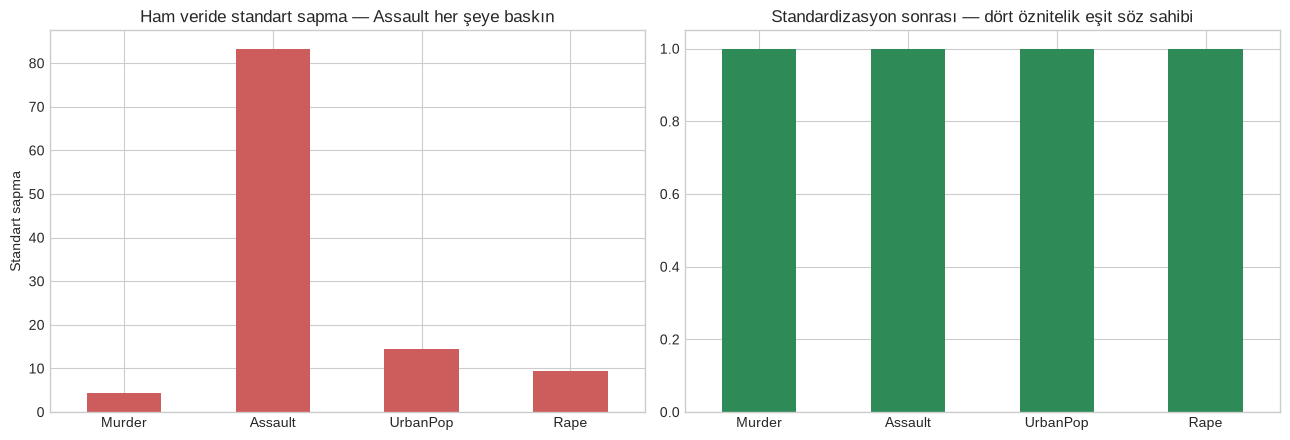

YORUM: Ham veride Assault'un standart sapması Murder'ınkinin kat kat üstünde; ölçeklemeden
uzaklık hesabı fiilen tek öznitelikle yapılır. Bu notebook boyunca ölçekli X_ar kullanılacak.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
arrests.std().plot(kind='bar', ax=axes[0], color='indianred')
axes[0].set_title('Ham veride standart sapma — Assault her şeye baskın')
axes[0].set_ylabel('Standart sapma'); axes[0].tick_params(axis='x', rotation=0)
pd.Series(X_ar.std(axis=0), index=arrests.columns).plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Standardizasyon sonrası — dört öznitelik eşit söz sahibi')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

print('YORUM: Ham veride Assault\'un standart sapması Murder\'ınkinin kat kat üstünde; ölçeklemeden')
print('uzaklık hesabı fiilen tek öznitelikle yapılır. Bu notebook boyunca ölçekli X_ar kullanılacak.')

## Adım 2 · Hiyerarşik Kümelemenin Sıfırdan Implementasyonu (4 Linkage)

**Ne yapıyoruz?** §2'deki algoritmayı **olduğu gibi** kodluyoruz: her adımda tüm aktif küme
çiftlerinin linkage uzaklığını hesapla, en küçüğünü birleştir. Bu naif sürüm $O(n^3)$'tür (50
nokta için saniyeler içinde biter, büyük veri için `scipy` kullanılır). Önce §2.3'teki
**5 noktalık elle örnekle** sonuçları kontrol ediyoruz, sonra `scipy.cluster.hierarchy.linkage`
ile USArrests üzerinde **birleşme yüksekliklerini** karşılaştırıyoruz.

Ward için `scipy`, yüksekliği $\sqrt{2\Delta}$ biçiminde raporlar ($\Delta$: §2.3'teki SSE artışı);
biz de aynı konvansiyonu kullanıyoruz, ham $\Delta$'yı da ayrıca saklıyoruz.

In [4]:
class SimpleAgglomerative:
    """Naif aglomeratif kümeleme (sıfırdan). linkage: 'single' | 'complete' | 'average' | 'ward'."""

    def __init__(self, linkage='ward'):
        self.linkage = linkage

    def _cluster_dist(self, X, D, A, B):
        if self.linkage == 'single':
            return D[np.ix_(A, B)].min()
        if self.linkage == 'complete':
            return D[np.ix_(A, B)].max()
        if self.linkage == 'average':
            return D[np.ix_(A, B)].mean()
        if self.linkage == 'ward':
            nA, nB = len(A), len(B)
            delta = nA * nB / (nA + nB) * np.sum((X[A].mean(0) - X[B].mean(0)) ** 2)
            return delta                      # ham SSE artışı
        raise ValueError(self.linkage)

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        D = squareform(pdist(X))
        members = {i: [i] for i in range(n)}   # küme_id -> üye indeksleri
        active = list(range(n))
        self.merges_ = []                       # (sol_id, sağ_id, yükseklik, boyut, ham_delta)
        next_id = n
        while len(active) > 1:
            best = None
            for i in range(len(active)):
                for j in range(i + 1, len(active)):
                    a, b = active[i], active[j]
                    h = self._cluster_dist(X, D, members[a], members[b])
                    if best is None or h < best[0]:
                        best = (h, a, b)
            h, a, b = best
            members[next_id] = members[a] + members[b]
            height = np.sqrt(2 * h) if self.linkage == 'ward' else h   # scipy konvansiyonu
            self.merges_.append((a, b, height, len(members[next_id]), h))
            active = [c for c in active if c not in (a, b)] + [next_id]
            next_id += 1
        self.members_ = members
        return self

    def heights(self):
        return np.array([m[2] for m in self.merges_])

    def cut(self, k):
        """Ağacı k kümeye keser: son (k-1) birleşmeyi geri al."""
        n = len(self.members_) - len(self.merges_)         # gözlem sayısı
        active = set(range(n))
        for step, (a, b, *_rest) in enumerate(self.merges_[: n - k]):
            active -= {a, b}
            active.add(n + step)
        labels = np.empty(n, dtype=int)
        for lab, cid in enumerate(sorted(active)):
            labels[self.members_[cid]] = lab
        return labels

print('SimpleAgglomerative tanımlandı.')

SimpleAgglomerative tanımlandı.


In [5]:
# --- 5 noktalık elle örnek (§2.3): A=1, B=2, C=6, D=8, E=15 ---
toy = np.array([[1.], [2.], [6.], [8.], [15.]])
names_toy = list('ABCDE')

print('Elle örnekteki birleşme yükseklikleri (sıfırdan kod):')
rows = []
for lk in ['single', 'complete', 'average', 'ward']:
    m = SimpleAgglomerative(lk).fit(toy)
    rows.append([lk] + [round(x, 2) for x in m.heights()])
toy_table = pd.DataFrame(rows, columns=['linkage', '1. birleşme', '2. birleşme', '3. birleşme', '4. birleşme'])
display(toy_table)

mw = SimpleAgglomerative('ward').fit(toy)
print('\nWard\'ın ham SSE artışları Δ (elle hesabımız: 0.5, 2.0, 30.25, 92.45):',
      [round(m[4], 2) for m in mw.merges_])

# scipy ile aynı sonuç mu?
for lk in ['single', 'complete', 'average', 'ward']:
    ours = SimpleAgglomerative(lk).fit(toy).heights()
    ref = linkage(toy, method=lk)[:, 2]
    print(f'{lk:9s} | max |fark| (sıfırdan - scipy) = {np.abs(ours - ref).max():.2e}')

print('\nYORUM: E noktası single linkage\'de 7\'de, complete linkage\'de 14\'te katılıyor — aynı veri,')
print('linkage kuralı "yakınlık"ı nasıl tanımladığına göre tamamen farklı bir hikaye anlatıyor.')

Elle örnekteki birleşme yükseklikleri (sıfırdan kod):


,linkage,1. birleşme,2. birleşme,3. birleşme,4. birleşme
0,single,1.0,2.0,4.00,7.00
1,complete,1.0,2.0,7.00,14.00
2,average,1.0,2.0,5.50,10.75
3,ward,1.0,2.0,7.78,13.60



Ward'ın ham SSE artışları Δ (elle hesabımız: 0.5, 2.0, 30.25, 92.45): [np.float64(0.5), np.float64(2.0), np.float64(30.25), np.float64(92.45)]
single    | max |fark| (sıfırdan - scipy) = 0.00e+00
complete  | max |fark| (sıfırdan - scipy) = 0.00e+00
average   | max |fark| (sıfırdan - scipy) = 0.00e+00
ward      | max |fark| (sıfırdan - scipy) = 0.00e+00

YORUM: E noktası single linkage'de 7'de, complete linkage'de 14'te katılıyor — aynı veri,
linkage kuralı "yakınlık"ı nasıl tanımladığına göre tamamen farklı bir hikaye anlatıyor.


In [6]:
# --- USArrests (ölçekli) üzerinde sıfırdan vs scipy ---
print('USArrests (50 eyalet, ölçekli) — birleşme yüksekliği karşılaştırması')
for lk in ['single', 'complete', 'average', 'ward']:
    t0 = time.perf_counter()
    mine = SimpleAgglomerative(lk).fit(X_ar)
    t_mine = time.perf_counter() - t0
    t0 = time.perf_counter()
    Z_ref = linkage(X_ar, method=lk)
    t_ref = time.perf_counter() - t0
    diff = np.abs(mine.heights() - Z_ref[:, 2]).max()
    # 4 kümelik kesimin scipy ile aynı olup olmadığı (ARI=1 -> birebir aynı bölümleme)
    ari = adjusted_rand_score(mine.cut(4), fcluster(Z_ref, 4, criterion='maxclust'))
    print(f'{lk:9s} | max yükseklik farkı={diff:.2e} | 4-küme kesimi ARI={ari:.3f} | '
          f'süre: sıfırdan {t_mine:.2f}s vs scipy {t_ref*1000:.2f}ms')

USArrests (50 eyalet, ölçekli) — birleşme yüksekliği karşılaştırması
single    | max yükseklik farkı=0.00e+00 | 4-küme kesimi ARI=1.000 | süre: sıfırdan 0.13s vs scipy 0.35ms


complete  | max yükseklik farkı=0.00e+00 | 4-küme kesimi ARI=1.000 | süre: sıfırdan 0.14s vs scipy 0.36ms
average   | max yükseklik farkı=8.88e-16 | 4-küme kesimi ARI=1.000 | süre: sıfırdan 0.17s vs scipy 0.35ms


ward      | max yükseklik farkı=1.78e-15 | 4-küme kesimi ARI=1.000 | süre: sıfırdan 0.35s vs scipy 0.34ms


## Adım 3 · Dendrogram Çizimi, Ağacı Kesme ve $k$ Seçimi

**Ne yapıyoruz?** `scipy.cluster.hierarchy.dendrogram` ile dört linkage'in ağacını çiziyoruz.
Sonra Ward ağacında **birleşme yüksekliklerine** bakıyoruz: §2.4'teki pratik kural gereği, $k$'yı
**büyük bir yükseklik sıçramasının** hemen öncesinde seçiyoruz. Çünkü büyük sıçrama = "bu
birleşme birbirinden gerçekten farklı iki grubu zorla birleştiriyor."

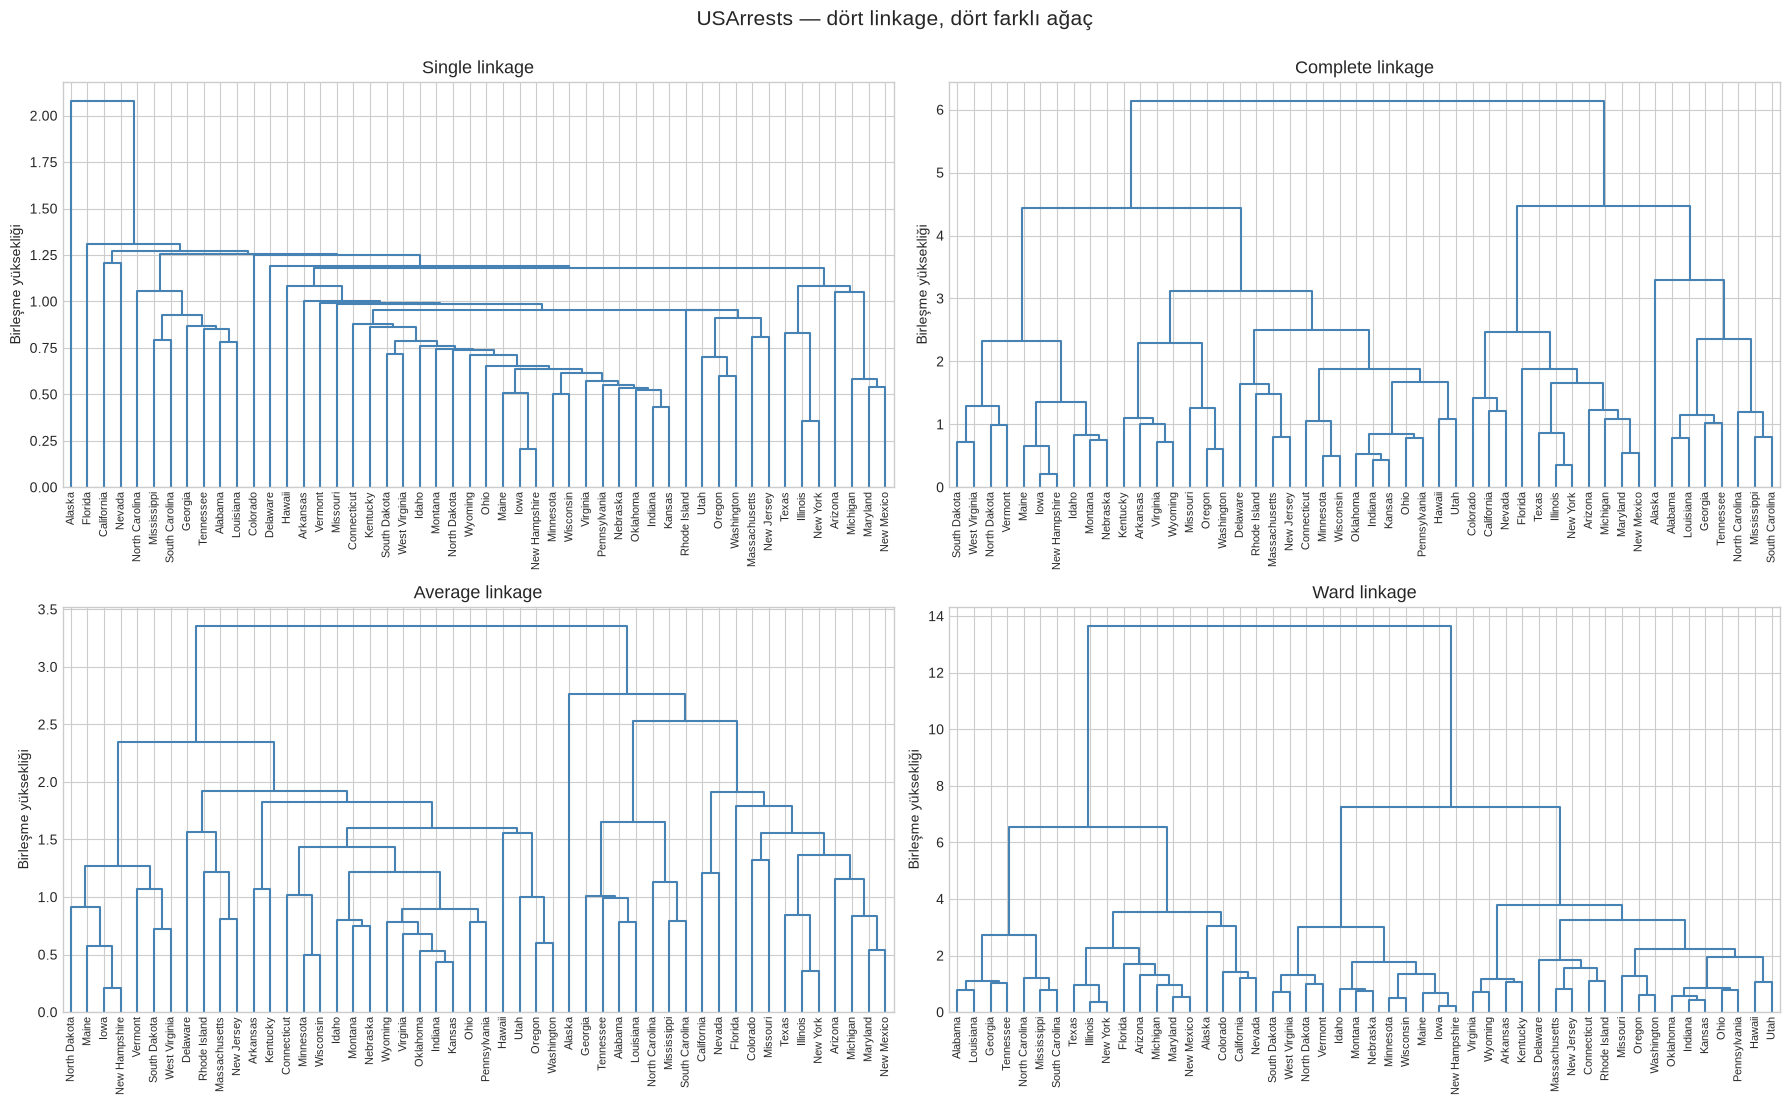

In [7]:
linkages = {lk: linkage(X_ar, method=lk) for lk in ['single', 'complete', 'average', 'ward']}

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, (lk, Z) in zip(axes.ravel(), linkages.items()):
    dendrogram(Z, labels=states, leaf_rotation=90, leaf_font_size=8, ax=ax,
               color_threshold=0.0, above_threshold_color='steelblue')
    ax.set_title(f'{lk.capitalize()} linkage', fontsize=13)
    ax.set_ylabel('Birleşme yüksekliği')
plt.suptitle('USArrests — dört linkage, dört farklı ağaç', fontsize=15, y=1.0)
plt.tight_layout(); plt.show()

,birleşme sonrası kalan küme sayısı,yükseklik,bir önceki birleşmeye göre sıçrama
0,10,2.265,NaN
1,9,2.742,0.477
2,8,3.024,0.282
3,7,3.056,0.032
4,6,3.243,0.188
5,5,3.532,0.288
6,4,3.772,0.240
7,3,6.527,2.755
8,2,7.261,0.734
9,1,13.653,6.392


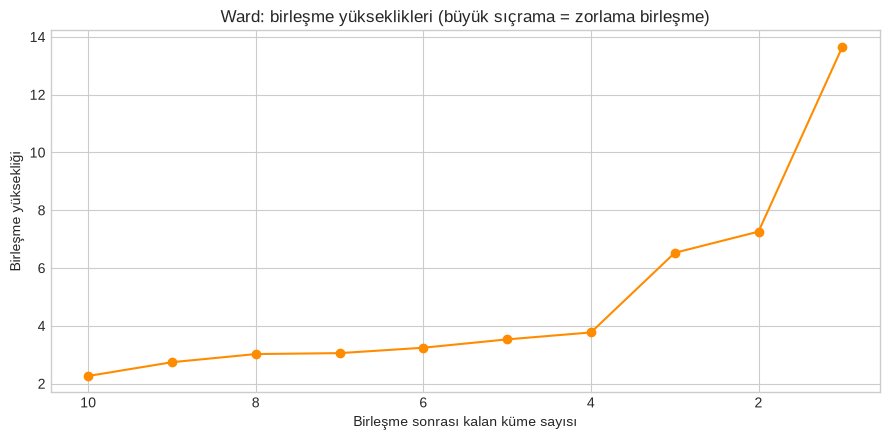


maxclust=4 ile distance<5.15 aynı bölümleme mi? ARI = 1.0


,k,k -> k-1 birleşme yüksekliği,bir önceki (k+1 -> k) yükseklik,sıçrama
0,2,13.653467,7.261168,6.392
2,4,6.527471,3.772026,2.755
1,3,7.261168,6.527471,0.734
8,10,2.742114,2.264942,0.477


YORUM: Sıçrama en büyük k=2 için (kaba "iki blok" ayrımı), ardından k=4 ve k=3.
Dendrogramın en tepesindeki birleşme neredeyse her zaman en büyük sıçramayı verir; bu yüzden k=2 çoğu zaman
"kaba ama güvenli" bir bölme, daha ince segmentasyon (k=3-4) ise iş amacına göre seçilen bir tercihtir.


In [8]:
Z_ward = linkages['ward']
heights = Z_ward[:, 2]

# Son 10 birleşmenin yükseklikleri ve ardışık sıçramalar
last = heights[-10:]
gap = np.diff(last)
tbl = pd.DataFrame({
    'birleşme sonrası kalan küme sayısı': np.arange(10, 0, -1),
    'yükseklik': last.round(3),
    'bir önceki birleşmeye göre sıçrama': np.r_[np.nan, gap.round(3)]
})
display(tbl)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(np.arange(10, 0, -1), last, 'o-', color='darkorange')
ax.set_xlabel('Birleşme sonrası kalan küme sayısı'); ax.set_ylabel('Birleşme yüksekliği')
ax.invert_xaxis(); ax.set_title('Ward: birleşme yükseklikleri (büyük sıçrama = zorlama birleşme)')
plt.tight_layout(); plt.show()

# Ağacı yüksek bir çizgiyle kesme: iki farklı yöntem aynı sonucu verir
labels_k4 = fcluster(Z_ward, t=4, criterion='maxclust')      # "tam 4 küme istiyorum"
cut_h = (heights[-4] + heights[-3]) / 2                      # 3. ve 4. son birleşme arasından
labels_h = fcluster(Z_ward, t=cut_h, criterion='distance')    # "şu yükseklikte kes"
print(f'\nmaxclust=4 ile distance<{cut_h:.2f} aynı bölümleme mi? ARI =',
      adjusted_rand_score(labels_k4, labels_h))

# Her aday k için: "k kümeden k-1 kümeye inen birleşme" ne kadar sıçrıyor? (büyük = k'yı korumak anlamlı)
cand = pd.DataFrame({'k': np.arange(2, 11),
                     'k -> k-1 birleşme yüksekliği': [heights[-(k - 1)] for k in range(2, 11)],
                     'bir önceki (k+1 -> k) yükseklik': [heights[-k] for k in range(2, 11)]})
cand['sıçrama'] = (cand.iloc[:, 1] - cand.iloc[:, 2]).round(3)
display(cand.sort_values('sıçrama', ascending=False).head(4))
top_k = cand.sort_values('sıçrama', ascending=False)['k'].tolist()
print(f'YORUM: Sıçrama en büyük k={top_k[0]} için (kaba "iki blok" ayrımı), ardından k={top_k[1]} ve k={top_k[2]}.')
print('Dendrogramın en tepesindeki birleşme neredeyse her zaman en büyük sıçramayı verir; bu yüzden k=2 çoğu zaman')
print('"kaba ama güvenli" bir bölme, daha ince segmentasyon (k=3-4) ise iş amacına göre seçilen bir tercihtir.')

## Adım 4 · Linkage Karşılaştırması: Zincirleme Etkisi ve Şekil Duyarlılığı

**Ne yapıyoruz?** Dört linkage'in **veri şekline** nasıl tepki verdiğini somut görmek için
**gerçek etiketleri bilinen** 4 sentetik veri üretiyoruz (3 yuvarlak küme, iki hilal, iç içe
halkalar, eğik/elips kümeler) ve her birinde gerçek $k$ ile kümeleme yapıp **ARI** hesaplıyoruz
(1 = mükemmel, ≈0 = rastgele). Beşinci bir seçenek olarak **bağlantı kısıtı (connectivity)
ile Ward** ekliyoruz: birleşmeyi sadece **$k$-en yakın komşu grafiğinde** komşu olan kümelerle
sınırlıyor — Ward'ın kompaktlık ilkesini koruyup yerel yapıyı da takip etmesini sağlıyor.

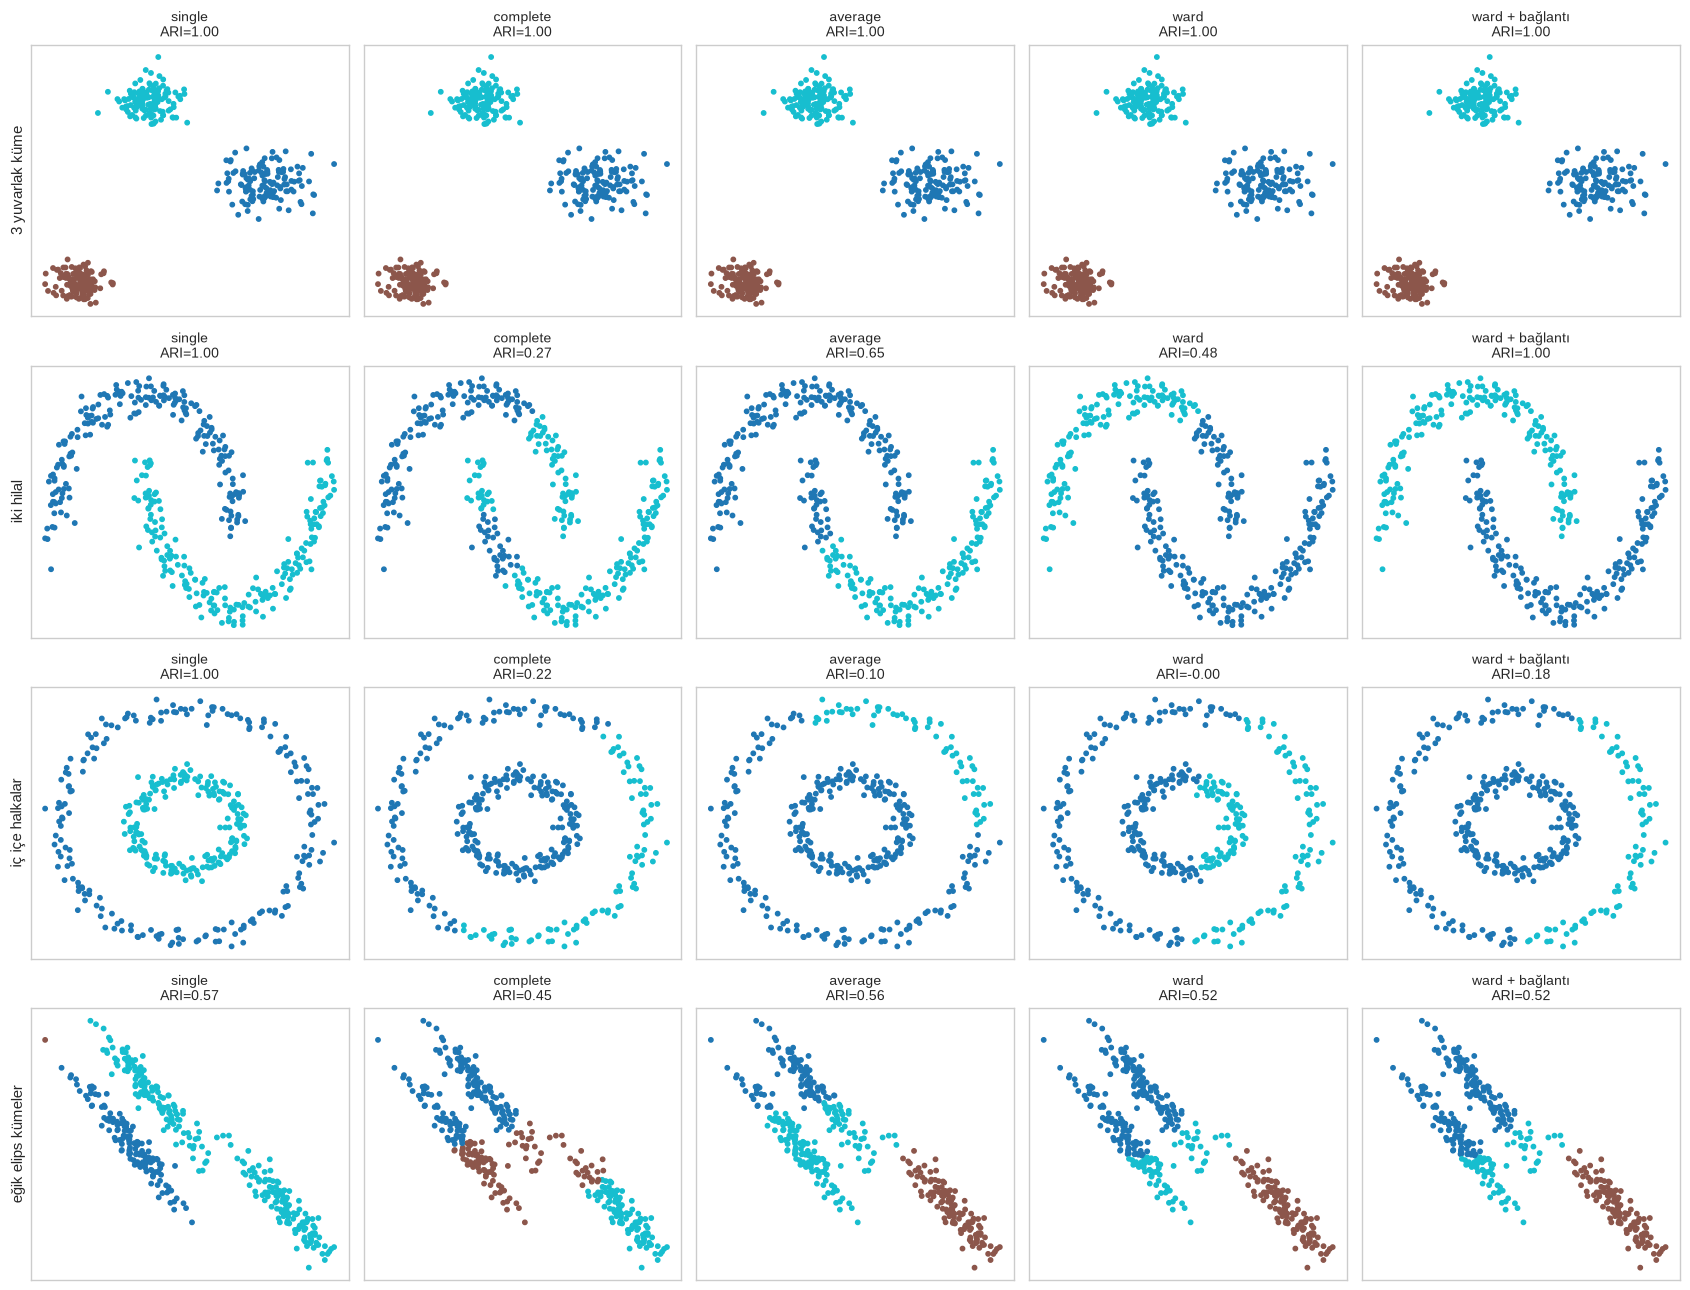

Not: 3 durumda 10-NN bağlantı grafiği tek parça değildi (ör. iç içe halkalar birbirine hiç komşu
olmayan iki ayrı bileşen oluşturur); scikit-learn grafiği otomatik tamamlıyor — bu beklenen bir davranış.


,single,complete,average,ward,ward + bağlantı
3 yuvarlak küme,1.00,1.00,1.00,1.00,1.00
iki hilal,1.00,0.27,0.65,0.48,1.00
iç içe halkalar,1.00,0.22,0.10,-0.00,0.18
eğik elips kümeler,0.57,0.45,0.56,0.52,0.52


YORUM: Single linkage, birbirinden ince boşlukla ayrılmış şekilli kümelerde (hilal, halka) mükemmel (ARI=1) ama
eğik/elips kümelerde zayıf; complete/average/Ward yuvarlak kümelerde iyi, hilal ve halkada başarısız. Bağlantı
kısıtı (10-NN grafiği) Ward'ı hilalde kurtarıyor ama iç içe halkalarda yetmiyor (iki halka grafikte hiç komşu değil).


In [9]:
def make_shapes(n=400, seed=42):
    rs = np.random.RandomState(seed)
    shapes = {}
    shapes['3 yuvarlak küme'] = make_blobs(n_samples=n, centers=3, cluster_std=[1.0, 1.4, 0.8], random_state=seed)
    shapes['iki hilal'] = make_moons(n_samples=n, noise=0.07, random_state=seed)
    shapes['iç içe halkalar'] = make_circles(n_samples=n, factor=0.4, noise=0.05, random_state=seed)
    Xb, yb = make_blobs(n_samples=n, centers=3, random_state=170)
    shapes['eğik elips kümeler'] = (Xb @ np.array([[0.6, -0.64], [-0.4, 0.85]]), yb)
    return shapes

shapes = make_shapes()
methods_h = ['single', 'complete', 'average', 'ward', 'ward + bağlantı']

res = {}
conn_warn = 0
fig, axes = plt.subplots(len(shapes), len(methods_h), figsize=(17, 13))
for r, (sname, (Xs, ys)) in enumerate(shapes.items()):
    Xs_sc = StandardScaler().fit_transform(Xs)
    k_true = len(np.unique(ys))
    for c, mth in enumerate(methods_h):
        with warnings.catch_warnings(record=True) as wlist:
            warnings.simplefilter('always')
            if mth == 'ward + bağlantı':
                conn = kneighbors_graph(Xs_sc, n_neighbors=10, include_self=False)
                model = AgglomerativeClustering(n_clusters=k_true, linkage='ward', connectivity=conn)
            else:
                model = AgglomerativeClustering(n_clusters=k_true, linkage=mth)
            lab = model.fit_predict(Xs_sc)
        conn_warn += sum('connected components' in str(w.message) for w in wlist)
        res[(sname, mth)] = adjusted_rand_score(ys, lab)
        axes[r, c].scatter(Xs_sc[:, 0], Xs_sc[:, 1], c=lab, cmap='tab10', s=10)
        axes[r, c].set_title(f'{mth}\nARI={res[(sname, mth)]:.2f}', fontsize=10)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(sname, fontsize=11)
plt.tight_layout(); plt.show()

print(f'Not: {conn_warn} durumda 10-NN bağlantı grafiği tek parça değildi (ör. iç içe halkalar birbirine hiç komşu')
print('olmayan iki ayrı bileşen oluşturur); scikit-learn grafiği otomatik tamamlıyor — bu beklenen bir davranış.')
ari_tbl = pd.Series(res).unstack().loc[list(shapes.keys()), methods_h].round(2)
display(ari_tbl)
print('YORUM: Single linkage, birbirinden ince boşlukla ayrılmış şekilli kümelerde (hilal, halka) mükemmel (ARI=1) ama')
print('eğik/elips kümelerde zayıf; complete/average/Ward yuvarlak kümelerde iyi, hilal ve halkada başarısız. Bağlantı')
print('kısıtı (10-NN grafiği) Ward\'ı hilalde kurtarıyor ama iç içe halkalarda yetmiyor (iki halka grafikte hiç komşu değil).')

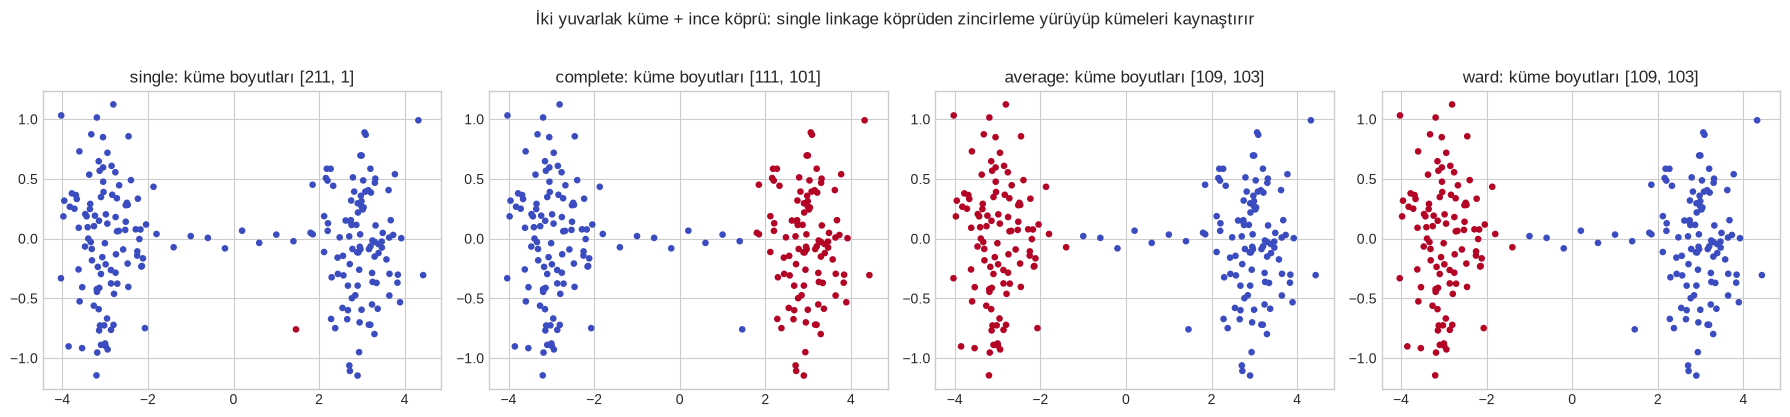

,küme boyutları,iki gerçek küme ayrıldı mı?
linkage,,
single,"[211, 1]",False
complete,"[111, 101]",True
average,"[109, 103]",True
ward,"[109, 103]",True


YORUM: Single linkage "en yakın iki nokta"ya baktığı için köprüdeki her nokta bir halka olur: iki gerçek küme TEK
parça sayılıyor ve ikinci küme olarak sadece tek bir uç nokta kopuyor (boyutlar ~[211, 1]). Complete, average ve
Ward kompakt grupları tercih ettiği için aynı köprüye rağmen iki kümeyi ayırıyor.


In [10]:
# Zincirleme etkisini (chaining) sayısal olarak gösterelim: iki yuvarlak küme + aralarında ince bir nokta köprüsü
rs = np.random.RandomState(7)
c1 = rs.normal([-3, 0], 0.5, size=(100, 2))
c2 = rs.normal([+3, 0], 0.5, size=(100, 2))
bridge = np.c_[np.linspace(-2.2, 2.2, 12), rs.normal(0, 0.05, 12)]     # 12 noktalık ince köprü
Xc = np.vstack([c1, c2, bridge]); yc = np.r_[np.zeros(100), np.ones(100), 2 * np.ones(12)]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
chain_rows = []
for ax, lk in zip(axes, ['single', 'complete', 'average', 'ward']):
    lab = AgglomerativeClustering(n_clusters=2, linkage=lk).fit_predict(Xc)
    sizes = np.bincount(lab, minlength=2)
    # iki gerçek küme (ilk 100 / sonraki 100 nokta) farklı etiketlerin çoğunluğunu mu alıyor?
    separated = np.bincount(lab[:100], minlength=2).argmax() != np.bincount(lab[100:200], minlength=2).argmax()
    chain_rows.append({'linkage': lk, 'küme boyutları': sizes.tolist(), 'iki gerçek küme ayrıldı mı?': bool(separated)})
    ax.scatter(Xc[:, 0], Xc[:, 1], c=lab, cmap='coolwarm', s=14)
    ax.set_title(f'{lk}: küme boyutları {sizes.tolist()}')
plt.suptitle('İki yuvarlak küme + ince köprü: single linkage köprüden zincirleme yürüyüp kümeleri kaynaştırır', y=1.03)
plt.tight_layout(); plt.show()
display(pd.DataFrame(chain_rows).set_index('linkage'))
print('YORUM: Single linkage "en yakın iki nokta"ya baktığı için köprüdeki her nokta bir halka olur: iki gerçek küme TEK')
print('parça sayılıyor ve ikinci küme olarak sadece tek bir uç nokta kopuyor (boyutlar ~[211, 1]). Complete, average ve')
print('Ward kompakt grupları tercih ettiği için aynı köprüye rağmen iki kümeyi ayırıyor.')

## Adım 5 · Kofenetik Korelasyon, Silhouette ile $k$ Seçimi ve Eyalet Kümelerinin Yorumu

**Ne yapıyoruz?** (1) Her linkage için **kofenetik korelasyonu** hesaplıyoruz: ağaçtaki
"birleşme yüksekliği" uzaklıkları ile gerçek ikili uzaklıklar ne kadar uyuşuyor? (2) Ward
ağacını $k=2,\dots,8$ için keserek **silhouette** skorlarını karşılaştırıyoruz (16'daki aracın
aynısı). (3) Seçtiğimiz $k$ için kümeleri **orijinal birimlerle** yorumluyoruz — eyaletleri
kümelere göre listeleyip ortalama suç oranlarına bakıyoruz.

Kofenetik korelasyon (1'e yakın = ağaç gerçek uzaklık yapısını iyi koruyor):


,cophenetic_corr
average,0.7180
complete,0.6979
ward,0.6975
single,0.5413


YORUM: En yüksek kofenetik korelasyon average (0.72), en düşük single (0.54): single linkage
zincirleme birleşmeler yüzünden gerçek uzaklık yapısını en çok bozan ağacı kuruyor. (Kofenetik korelasyon ağacın
uzaklık sadakatini ölçer, kümelerin kalitesini değil — yüksek olması "daha iyi kümeleme" demek değildir.)

Ward dendrogramını k kümeye keserek silhouette:
2    0.4048
3    0.3104
4    0.3370
5    0.2731
6    0.2617
7    0.2603
8    0.2637


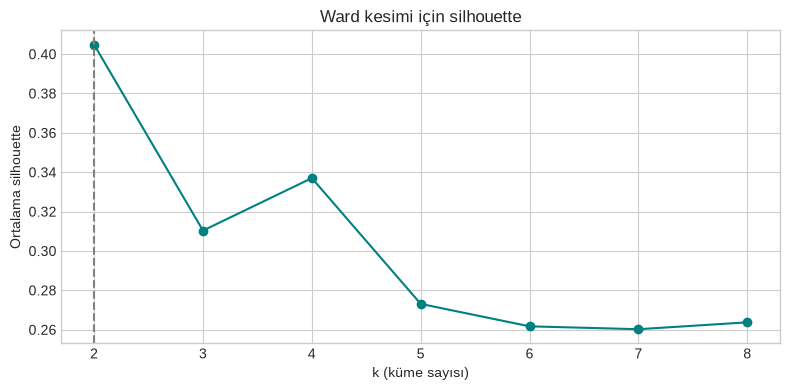


YORUM: Silhouette en yüksek k=2 (kaba "yüksek suç / düşük suç" ayrımı) — Adım 3'teki sıçrama analiziyle aynı öneri.
k=2'den sonra silhouette'in yerel zirve yaptığı değer(ler): [4] (sıçrama sıralamasında da k=4 ikinci geliyordu).
Yani iki bağımsız ölçüt k=2 (kaba) ve k=4 (ince) etrafında uzlaşıyor; hangisini seçeceğimiz iş amacına bağlı.


In [11]:
true_d = pdist(X_ar)
coph = {}
for lk, Z in linkages.items():
    c, _ = cophenet(Z, true_d)
    coph[lk] = c
coph_s = pd.Series(coph).round(4).sort_values(ascending=False)
print('Kofenetik korelasyon (1\'e yakın = ağaç gerçek uzaklık yapısını iyi koruyor):')
display(coph_s.to_frame('cophenetic_corr'))
print(f'YORUM: En yüksek kofenetik korelasyon {coph_s.index[0]} ({coph_s.iloc[0]:.2f}), en düşük {coph_s.index[-1]} ({coph_s.iloc[-1]:.2f}): single linkage')
print('zincirleme birleşmeler yüzünden gerçek uzaklık yapısını en çok bozan ağacı kuruyor. (Kofenetik korelasyon ağacın')
print('uzaklık sadakatini ölçer, kümelerin kalitesini değil — yüksek olması "daha iyi kümeleme" demek değildir.)')

# Ward ağacı: k = 2..8 silhouette
sil = {}
for k in range(2, 9):
    lab = fcluster(Z_ward, t=k, criterion='maxclust')
    sil[k] = silhouette_score(X_ar, lab)
sil_s = pd.Series(sil)
best_k_ar = int(sil_s.idxmax())
print('\nWard dendrogramını k kümeye keserek silhouette:')
print(sil_s.round(4).to_string())

plt.figure(figsize=(8, 4))
plt.plot(sil_s.index, sil_s.values, 'o-', color='teal'); plt.axvline(best_k_ar, ls='--', color='gray')
plt.xlabel('k (küme sayısı)'); plt.ylabel('Ortalama silhouette'); plt.title('Ward kesimi için silhouette')
plt.tight_layout(); plt.show()
local_peaks = [k for k in range(3, 8) if sil_s[k] > sil_s[k - 1] and sil_s[k] > sil_s[k + 1]]
print(f'\nYORUM: Silhouette en yüksek k={best_k_ar} (kaba "yüksek suç / düşük suç" ayrımı) — Adım 3\'teki sıçrama analiziyle aynı öneri.')
print(f'k=2\'den sonra silhouette\'in yerel zirve yaptığı değer(ler): {local_peaks} (sıçrama sıralamasında da k=4 ikinci geliyordu).')
print('Yani iki bağımsız ölçüt k=2 (kaba) ve k=4 (ince) etrafında uzlaşıyor; hangisini seçeceğimiz iş amacına bağlı.')

In [12]:
K_AR = 4    # k=2 kaba bir 'yüksek/düşük suç' ayrımı verir; silhouette'te k=2'den sonraki yerel zirve k=4 -> daha ince profil için 4'ü seçiyoruz
arrests['cluster_ward'] = fcluster(Z_ward, t=K_AR, criterion='maxclust')

profile = arrests.groupby('cluster_ward')[['Murder', 'Assault', 'Rape', 'UrbanPop']].mean().round(1)
profile['n_eyalet'] = arrests['cluster_ward'].value_counts().sort_index()
display(profile)

for cl, grp in arrests.groupby('cluster_ward'):
    print(f'Küme {cl} ({len(grp)} eyalet): ' + ', '.join(grp.index))

# K-Means (16'daki yöntem) ile aynı bölümleme mi?
km_ar = KMeans(n_clusters=K_AR, init='k-means++', n_init=10, random_state=42).fit(X_ar)
print(f'\nWard (k={K_AR}) vs K-Means (k={K_AR}) ARI = {adjusted_rand_score(arrests["cluster_ward"], km_ar.labels_):.3f}')
print('YORUM (ortalamalar ve eyalet listeleri birlikte okununca): Küme 1 en yüksek cinayet oranı + düşük kentleşme (Güney')
print('eyaletleri); Küme 2 yüksek saldırı + en yüksek tecavüz + yüksek kentleşme (California, New York, Texas, Florida...);')
print('Küme 3 her suç türünde en düşük (Dakotalar, Vermont, Maine...); Küme 4 orta düzey. Hiyerarşik kümelemenin çıktısı sadece')
print('etiket değil, "hangi eyaletler birbirine benzer?" sorusuna yorumlanabilir bir ağaç da veriyor.')

,Murder,Assault,Rape,UrbanPop,n_eyalet
cluster_ward,,,,,
1,14.7,251.3,21.7,54.3,7
2,11.0,264.0,33.6,76.5,12
3,3.1,76.0,11.8,52.1,12
4,6.2,142.1,19.2,71.3,19


Küme 1 (7 eyalet): Alabama, Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee
Küme 2 (12 eyalet): Alaska, Arizona, California, Colorado, Florida, Illinois, Maryland, Michigan, Nevada, New Mexico, New York, Texas
Küme 3 (12 eyalet): Idaho, Iowa, Maine, Minnesota, Montana, Nebraska, New Hampshire, North Dakota, South Dakota, Vermont, West Virginia, Wisconsin
Küme 4 (19 eyalet): Arkansas, Connecticut, Delaware, Hawaii, Indiana, Kansas, Kentucky, Massachusetts, Missouri, New Jersey, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, Utah, Virginia, Washington, Wyoming

Ward (k=4) vs K-Means (k=4) ARI = 0.824
YORUM (ortalamalar ve eyalet listeleri birlikte okununca): Küme 1 en yüksek cinayet oranı + düşük kentleşme (Güney
eyaletleri); Küme 2 yüksek saldırı + en yüksek tecavüz + yüksek kentleşme (California, New York, Texas, Florida...);
Küme 3 her suç türünde en düşük (Dakotalar, Vermont, Maine...); Küme 4 orta düzey. Hiyerarşik kümelemenin çıktısı sadece
etiket de

## Adım 6 · `quakes` Verisinin Yüklenmesi ve Coğrafi Keşfi

**Ne yapıyoruz?** **quakes** verisini yüklüyoruz (Fiji adaları çevresinde, 1964'ten itibaren
kaydedilen ve büyüklüğü 4.0'ın üstünde olan **1000 deprem**; R `datasets` paketi — Harvard
sismoloji kayıtlarından). Sütunlar: `lat` (enlem), `long` (boylam, 0-360° gösterimi, yani
180°'nin ötesi Doğu yarım küredir), `depth` (odak derinliği, km), `mag` (büyüklük),
`stations` (depremi raporlayan istasyon sayısı).

Bölge, **iki tektonik plakanın birbirinin altına daldığı** (subduction) bir sınırdır — depremler
rastgele dağılmaz, plaka sınırı boyunca **şerit şeklinde** yoğunlaşır. Bu tam olarak DBSCAN'in
parladığı durum: yuvarlak olmayan, uzamış yoğun bölgeler + aralarda dağınık deprem.

**Önemli ayrıntı — mesafe birimi:** Enlem-boylam **derece** cinsindendir ve yer **küre**dir. 1°
enlem her yerde ≈111 km'dir ama 1° boylam, kutuplara yaklaştıkça **kısalır** (ekvatorda ≈111
km, enlem $\phi$'de $111\cos\phi$ km). Derece üzerinde Öklid uzaklığı kullanırsak $\varepsilon$
"kaç km?" sorusunu cevaplayamayız. Bunun yerine **haversine** (küre üzerindeki büyük-daire)
uzaklığı kullanıp $\varepsilon$'u doğrudan **kilometre** cinsinden vereceğiz.

quakes: (1000, 5) | eksik değer: 0


,lat,long,depth,mag,stations
count,1000.00,1000.00,1000.00,1000.00,1000.00
mean,-20.64,179.46,311.37,4.62,33.42
std,5.03,6.07,215.54,0.40,21.90
min,-38.59,165.67,40.00,4.00,10.00
25%,-23.47,179.62,99.00,4.30,18.00
50%,-20.30,181.41,247.00,4.60,27.00
75%,-17.64,183.20,543.00,4.90,42.00
max,-10.72,188.13,680.00,6.40,132.00



Ortalama enlem -20.6° -> 1° enlem ≈ 111 km, 1° boylam ≈ 104 km


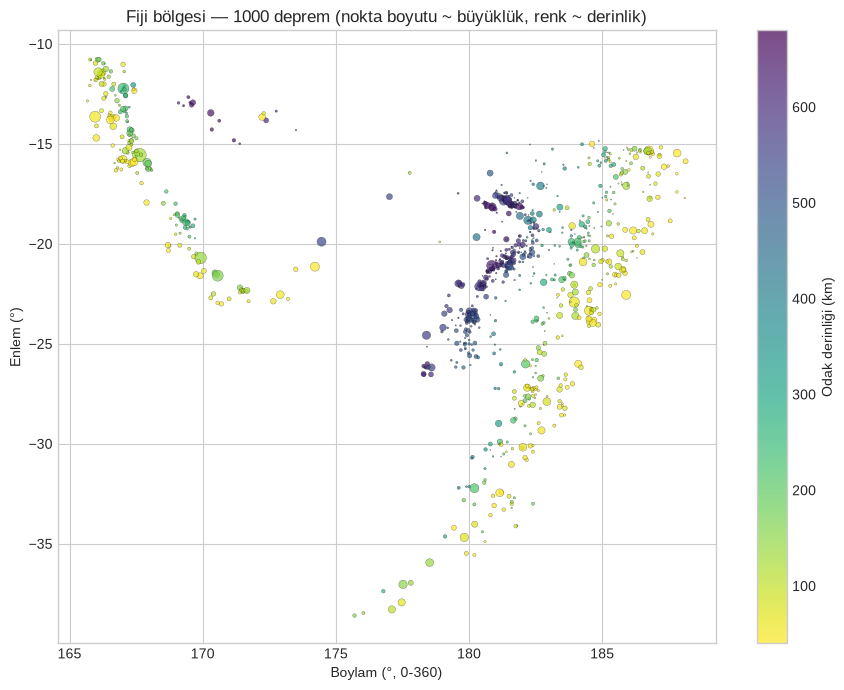

In [13]:
quakes = pd.read_csv('data/quakes.csv', index_col=0)
print('quakes:', quakes.shape, '| eksik değer:', int(quakes.isna().sum().sum()))
display(quakes.describe().round(2))

# Somut: 1 derece boylam kaç km? (enlem -20 civarında)
lat0 = quakes['lat'].mean()
print(f'\nOrtalama enlem {lat0:.1f}° -> 1° enlem ≈ 111 km, 1° boylam ≈ {111*np.cos(np.radians(lat0)):.0f} km')

EARTH_R = 6371.0     # km
R_rad = np.radians(quakes[['lat', 'long']].to_numpy())     # haversine radyan ve (enlem, boylam) sırası bekler

fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(quakes['long'], quakes['lat'], c=quakes['depth'], s=(quakes['mag'] - 3.5) ** 3 * 4,
                cmap='viridis_r', alpha=0.7, edgecolor='k', linewidth=0.2)
plt.colorbar(sc, label='Odak derinliği (km)')
ax.set_xlabel('Boylam (°, 0-360)'); ax.set_ylabel('Enlem (°)')
ax.set_title('Fiji bölgesi — 1000 deprem (nokta boyutu ~ büyüklük, renk ~ derinlik)')
plt.tight_layout(); plt.show()

## Adım 7 · DBSCAN'in 1B Elle Örneği ve Sıfırdan Implementasyonu

**Ne yapıyoruz?** §3.4'teki 9 noktalık örnekte her noktanın $\varepsilon$-komşu sayısını **elle
tablo halinde** hesaplayıp çekirdek / sınır / gürültü türlerini ayırıyoruz. Sonra DBSCAN'i
**sıfırdan** yazıyoruz: önce her noktanın komşu listesi ($\varepsilon$-sorgusu), sonra çekirdek
noktalardan başlayıp "yürüyerek ulaşılabilen" her şeyi aynı kümeye ekleyen bir genişleme
(BFS) döngüsü. Aynı sınıfı daha sonra gerçek veride `sklearn` ile karşılaştıracağız.

In [14]:
from sklearn.metrics.pairwise import pairwise_distances, haversine_distances

class SimpleDBSCAN:
    """DBSCAN (sıfırdan). metric='euclidean' veya 'haversine' (girdi radyan, eps radyan)."""

    def __init__(self, eps=0.5, min_samples=5, metric='euclidean'):
        self.eps, self.min_samples, self.metric = eps, min_samples, metric

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        D = haversine_distances(X) if self.metric == 'haversine' else pairwise_distances(X)
        # 1) eps-sorgusu: her noktanın komşu listesi (kendisi dahil)
        self.neighbors_ = [np.where(D[i] <= self.eps)[0] for i in range(n)]
        self.n_neighbors_ = np.array([len(nb) for nb in self.neighbors_])
        # 2) çekirdek noktalar
        self.core_mask_ = self.n_neighbors_ >= self.min_samples
        # 3) çekirdek noktalardan genişleyerek kümeleri kur
        labels = -np.ones(n, dtype=int)
        cid = 0
        for i in range(n):
            if labels[i] != -1 or not self.core_mask_[i]:
                continue
            labels[i] = cid
            frontier = [i]
            while frontier:
                p = frontier.pop()
                if not self.core_mask_[p]:
                    continue                      # sınır noktaya ulaşıldı: kümeye katılır ama genişletmez
                for q in self.neighbors_[p]:
                    if labels[q] == -1:
                        labels[q] = cid
                        frontier.append(q)
            cid += 1
        self.labels_ = labels
        return self

    def point_types(self):
        t = np.where(self.core_mask_, 'çekirdek', np.where(self.labels_ >= 0, 'sınır', 'gürültü'))
        return t

print('SimpleDBSCAN tanımlandı.')

SimpleDBSCAN tanımlandı.


In [15]:
# --- §3.4 elle örnek: eps=0.55, minPts=3 ---
toy_pts = np.array([1.0, 1.2, 1.4, 1.9, 2.9, 5.0, 5.1, 5.2, 8.0]).reshape(-1, 1)
my_toy = SimpleDBSCAN(eps=0.55, min_samples=3).fit(toy_pts)

toy_tbl = pd.DataFrame({
    'nokta': toy_pts.ravel(),
    'komşu sayısı (kendisi dahil)': my_toy.n_neighbors_,
    'tür': my_toy.point_types(),
    'küme etiketi': my_toy.labels_,
})
display(toy_tbl)

sk_toy = DBSCAN(eps=0.55, min_samples=3).fit(toy_pts)
print('sıfırdan etiketler :', my_toy.labels_.tolist())
print('sklearn etiketler  :', sk_toy.labels_.tolist())
print('Tam eşleşme:', np.array_equal(my_toy.labels_, sk_toy.labels_))
print('\nYORUM: 1.9 kendi başına kalabalık değil (2 komşu < 3) ama çekirdek 1.4\'ün komşusu olduğu için kümeye SINIR')
print('noktası olarak giriyor; 2.9 ve 8.0 hiçbir çekirdeğe yakın olmadığı için GÜRÜLTÜ — K-Means bu iki noktayı da')
print('mutlaka bir kümeye koymak zorunda kalırdı.')

,nokta,komşu sayısı (kendisi dahil),tür,küme etiketi
0,1.0,3,çekirdek,0
1,1.2,3,çekirdek,0
2,1.4,4,çekirdek,0
3,1.9,2,sınır,0
4,2.9,1,gürültü,-1
5,5.0,3,çekirdek,1
6,5.1,3,çekirdek,1
7,5.2,3,çekirdek,1
8,8.0,1,gürültü,-1


sıfırdan etiketler : [0, 0, 0, 0, -1, 1, 1, 1, -1]
sklearn etiketler  : [0, 0, 0, 0, -1, 1, 1, 1, -1]
Tam eşleşme: True

YORUM: 1.9 kendi başına kalabalık değil (2 komşu < 3) ama çekirdek 1.4'ün komşusu olduğu için kümeye SINIR
noktası olarak giriyor; 2.9 ve 8.0 hiçbir çekirdeğe yakın olmadığı için GÜRÜLTÜ — K-Means bu iki noktayı da
mutlaka bir kümeye koymak zorunda kalırdı.


## Adım 8 · $k$-Uzaklık Grafiği ile $\varepsilon$ Seçimi ve Gerçek Veride DBSCAN

**Ne yapıyoruz?** §3.5'teki yöntemi uyguluyoruz: `minPts=10` seçip her depremin **10. en yakın
komşusuna** olan uzaklığını (km) hesaplıyoruz, sıralayıp çiziyoruz. Eğrinin "dirsek" yaptığı
bölge $\varepsilon$ adayıdır. Sonra `sklearn.cluster.DBSCAN`'i **haversine** uzaklığıyla
($\varepsilon$ km cinsinden, `eps = km / 6371` radyana çevrilerek) çalıştırıp **sıfırdan
sınıfımızla doğruluyoruz**.

10-uzaklık yüzdelikleri (km): {50: 50.1, 75: 77.0, 90: 111.3, 95: 137.7, 99: 290.7}


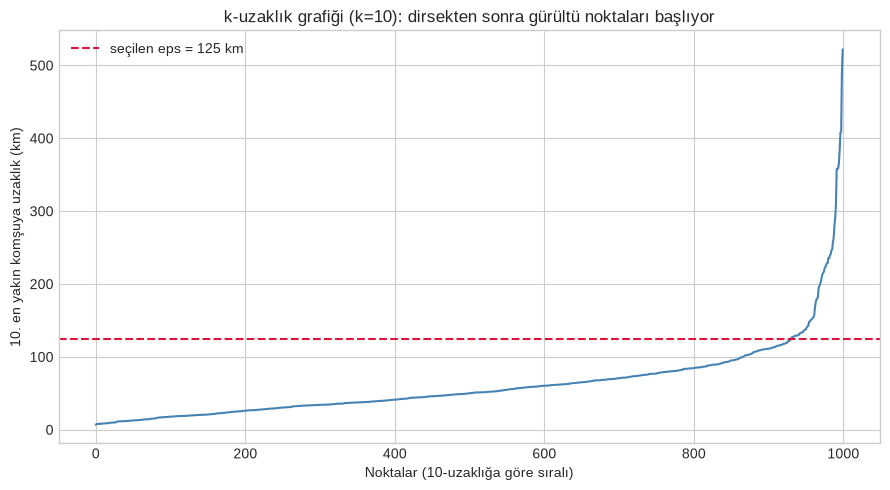

YORUM: Eğri ilk ~%90-95'te yavaş yükseliyor (yoğun bölgedeki noktalar), sonra diklesiyor (izole depremler).
Dirsek bölgesindeki bir değer olan eps=125 km ile devam ediyoruz.


In [16]:
MIN_SAMPLES = 10
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='haversine').fit(R_rad)
dist_rad, _ = nn.kneighbors(R_rad)
kdist_km = np.sort(dist_rad[:, -1] * EARTH_R)         # her noktanın 10. komşusuna uzaklık (km), sıralı

print('10-uzaklık yüzdelikleri (km):', {p: round(float(np.percentile(kdist_km, p)), 1) for p in [50, 75, 90, 95, 99]})

EPS_KM = 125
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(kdist_km, color='steelblue')
ax.axhline(EPS_KM, color='crimson', ls='--', label=f'seçilen eps = {EPS_KM} km')
ax.set_xlabel('Noktalar (10-uzaklığa göre sıralı)'); ax.set_ylabel('10. en yakın komşuya uzaklık (km)')
ax.set_title('k-uzaklık grafiği (k=10): dirsekten sonra gürültü noktaları başlıyor')
ax.legend(); plt.tight_layout(); plt.show()
print('YORUM: Eğri ilk ~%90-95\'te yavaş yükseliyor (yoğun bölgedeki noktalar), sonra diklesiyor (izole depremler).')
print(f'Dirsek bölgesindeki bir değer olan eps={EPS_KM} km ile devam ediyoruz.')

In [17]:
db = DBSCAN(eps=EPS_KM / EARTH_R, min_samples=MIN_SAMPLES, metric='haversine', algorithm='ball_tree').fit(R_rad)
quakes['db_label'] = db.labels_
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f'DBSCAN (eps={EPS_KM} km, minPts={MIN_SAMPLES}) | küme sayısı={n_clusters} | gürültü={int((db.labels_ == -1).sum())} deprem')
print('Küme boyutları (-1 = gürültü):'); print(pd.Series(db.labels_).value_counts().sort_index().to_string())

# --- sıfırdan implementasyonla doğrulama ---
my_db = SimpleDBSCAN(eps=EPS_KM / EARTH_R, min_samples=MIN_SAMPLES, metric='haversine').fit(R_rad)
print('\nSıfırdan vs sklearn: etiketler birebir aynı mı?', np.array_equal(my_db.labels_, db.labels_))
print('Çekirdek nokta maskesi aynı mı?', np.array_equal(my_db.core_mask_, np.isin(np.arange(len(R_rad)), db.core_sample_indices_)))

# --- küme profilleri ---
prof = quakes.groupby('db_label')[['long', 'lat', 'depth', 'mag']].agg(['mean']).round(1)
prof.columns = ['ort. boylam', 'ort. enlem', 'ort. derinlik (km)', 'ort. büyüklük']
prof.insert(0, 'n', quakes['db_label'].value_counts().sort_index())
display(prof)

DBSCAN (eps=125 km, minPts=10) | küme sayısı=3 | gürültü=40 deprem
Küme boyutları (-1 = gürültü):
-1     40
 0    776
 1    122
 2     62



Sıfırdan vs sklearn: etiketler birebir aynı mı? True
Çekirdek nokta maskesi aynı mı? True


,n,ort. boylam,ort. enlem,ort. derinlik (km),ort. büyüklük
db_label,,,,,
-1,40,175.0,-23.1,318.1,4.9
0,776,182.4,-21.6,352.7,4.6
1,122,166.9,-13.7,128.4,4.8
2,62,169.9,-20.3,150.3,4.8


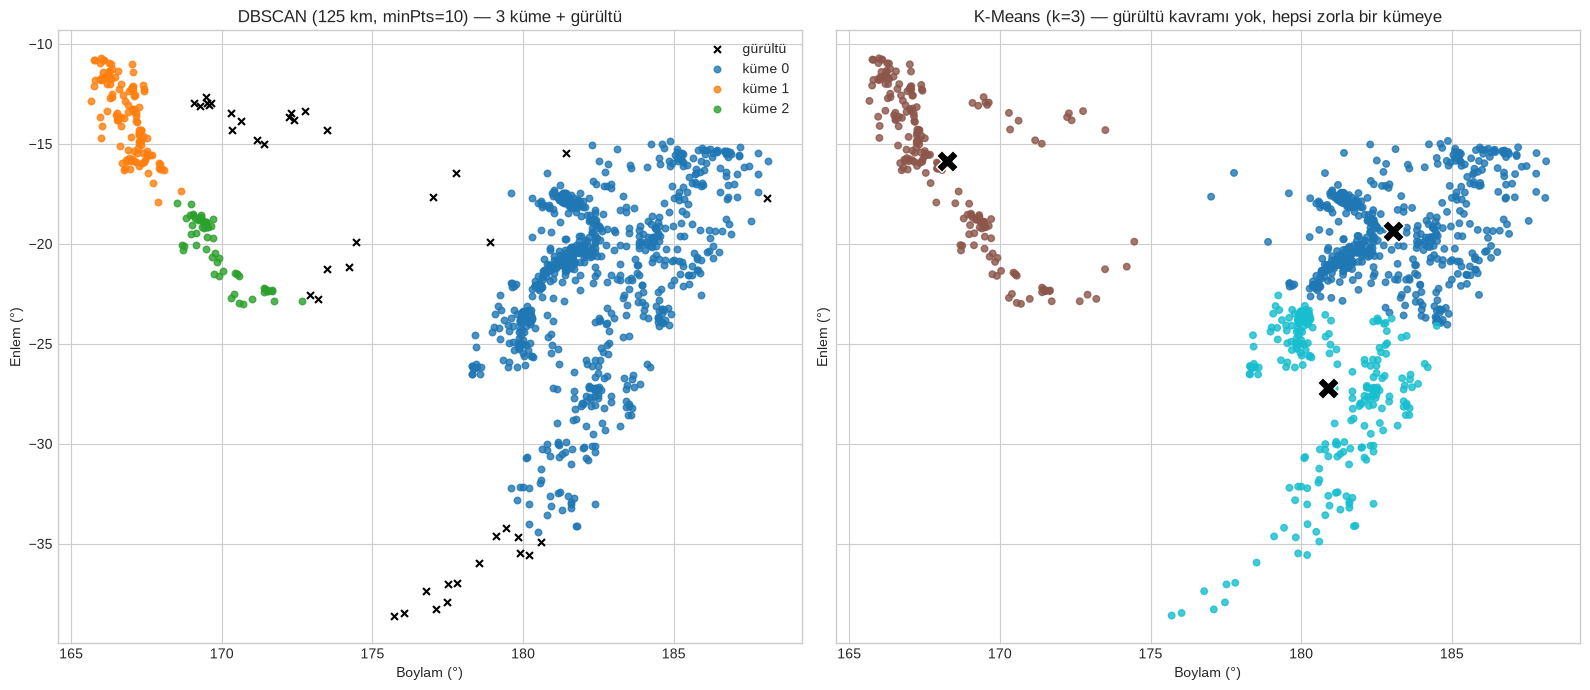

K-Means küme boyutları: [540, 205, 255]
YORUM: DBSCAN, depremlerin gerçekte plaka sınırı boyunca uzanan yoğun şeritler olduğunu şekil varsayımı
yapmadan buluyor ve dağınık depremleri ayrıca gürültü olarak işaretliyor. K-Means yalnızca merkezlere olan
uzaklığa baktığı için şeritleri keyfi yerlerden "dilimliyor".


In [18]:
# K-Means ile yan yana (aynı küme sayısı: DBSCAN'in bulduğu)
km_q = KMeans(n_clusters=n_clusters, init='k-means++', n_init=10, random_state=42).fit(quakes[['lat', 'long']])

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
palette = plt.get_cmap('tab10')
for lab in sorted(set(db.labels_)):
    m = db.labels_ == lab
    if lab == -1:
        axes[0].scatter(quakes.loc[m, 'long'], quakes.loc[m, 'lat'], c='k', marker='x', s=25, label='gürültü')
    else:
        axes[0].scatter(quakes.loc[m, 'long'], quakes.loc[m, 'lat'], color=palette(lab), s=22, alpha=0.8, label=f'küme {lab}')
axes[0].set_title(f'DBSCAN ({EPS_KM} km, minPts={MIN_SAMPLES}) — {n_clusters} küme + gürültü'); axes[0].legend()
axes[1].scatter(quakes['long'], quakes['lat'], c=km_q.labels_, cmap='tab10', s=22, alpha=0.8)
axes[1].scatter(km_q.cluster_centers_[:, 1], km_q.cluster_centers_[:, 0], c='k', marker='X', s=250, edgecolor='w')
axes[1].set_title(f'K-Means (k={n_clusters}) — gürültü kavramı yok, hepsi zorla bir kümeye')
for ax in axes: ax.set_xlabel('Boylam (°)'); ax.set_ylabel('Enlem (°)')
plt.tight_layout(); plt.show()

print('K-Means küme boyutları:', np.bincount(km_q.labels_).tolist())
print('YORUM: DBSCAN, depremlerin gerçekte plaka sınırı boyunca uzanan yoğun şeritler olduğunu şekil varsayımı')
print('yapmadan buluyor ve dağınık depremleri ayrıca gürültü olarak işaretliyor. K-Means yalnızca merkezlere olan')
print('uzaklığa baktığı için şeritleri keyfi yerlerden "dilimliyor".')

## Adım 9 · $\varepsilon$ × minPts Duyarlılığı

**Ne yapıyoruz?** DBSCAN'in iki parametresine ne kadar duyarlı olduğunu görmek için bir
**ızgara (grid)** tarıyoruz: farklı $\varepsilon$ (km) ve minPts kombinasyonlarında **küme
sayısını** ve **gürültü oranını** tablolaştırıyoruz. Beklenti (§3.6): küçük $\varepsilon$ →
çok sayıda küçük küme ve çok gürültü; büyük $\varepsilon$ → kümeler tek bir dev kümeye
**kaynaşır**.

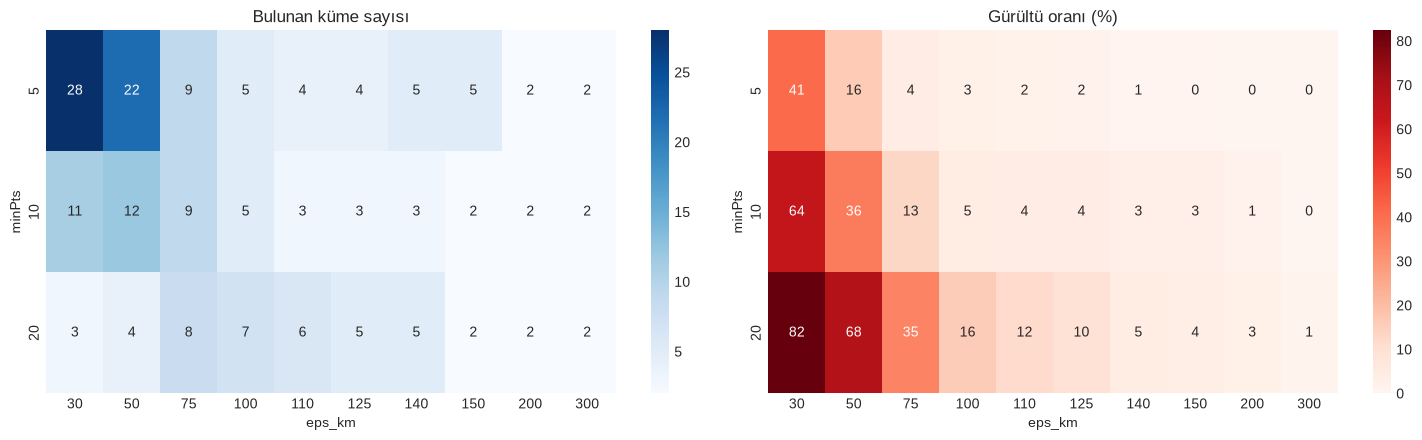

YORUM: minPts=10 satırında en uzun "sabit sonuç" bölgesi eps=110-140 km (3 küme) —
bu bir plato: parametre bu aralıkta biraz oynasa da sonuç değişmiyor. Plato dışında: küçük eps/büyük minPts köşesinde
neredeyse her şey gürültü, büyük eps köşesinde 1-2 dev küme kalıyor. Platoyu bulmak (k-uzaklık grafiği + bu tablo
birlikte) pratikte DBSCAN ayarlamanın asıl işidir.


In [19]:
eps_grid = [30, 50, 75, 100, 110, 125, 140, 150, 200, 300]
ms_grid = [5, 10, 20]
rows = []
for ms in ms_grid:
    for e in eps_grid:
        lab = DBSCAN(eps=e / EARTH_R, min_samples=ms, metric='haversine', algorithm='ball_tree').fit_predict(R_rad)
        rows.append({'minPts': ms, 'eps_km': e,
                     'küme': len(set(lab)) - (1 if -1 in lab else 0),
                     'gürültü_%': 100 * (lab == -1).mean()})
grid = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(grid.pivot(index='minPts', columns='eps_km', values='küme'), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Bulunan küme sayısı')
sns.heatmap(grid.pivot(index='minPts', columns='eps_km', values='gürültü_%'), annot=True, fmt='.0f', cmap='Reds', ax=axes[1])
axes[1].set_title('Gürültü oranı (%)')
plt.tight_layout(); plt.show()

row10 = grid[grid['minPts'] == 10].set_index('eps_km')['küme']
runs, cur = [], [row10.index[0]]
for e_prev, e in zip(row10.index[:-1], row10.index[1:]):
    if row10[e] == row10[e_prev] and row10[e] >= 2:
        cur.append(e)
    else:
        runs.append(cur); cur = [e]
runs.append(cur)
best_run = max(runs, key=len)
print(f'YORUM: minPts=10 satırında en uzun "sabit sonuç" bölgesi eps={best_run[0]}-{best_run[-1]} km ({int(row10[best_run[0]])} küme) —')
print('bu bir plato: parametre bu aralıkta biraz oynasa da sonuç değişmiyor. Plato dışında: küçük eps/büyük minPts köşesinde')
print('neredeyse her şey gürültü, büyük eps köşesinde 1-2 dev küme kalıyor. Platoyu bulmak (k-uzaklık grafiği + bu tablo')
print('birlikte) pratikte DBSCAN ayarlamanın asıl işidir.')

## Adım 10 · Farklı Yoğunluklu Kümeler: DBSCAN'in Zayıflığı, OPTICS ve HDBSCAN

**Ne yapıyoruz?** §3.6'daki en önemli zayıflığı somut gösteriyoruz: **iki sıkı (yoğun)** küme
birbirine yakın, **bir seyrek (dağınık)** küme uzakta. Tek bir $\varepsilon$ iki ihtiyacı
birden karşılayamaz: sıkı kümeleri ayırmak için küçük $\varepsilon$ gerekir, ama o zaman
seyrek küme "gürültü" olur; seyrek kümeyi yakalamak için büyük $\varepsilon$ seçersek iki sıkı
küme birleşir. Sonra **OPTICS** ve **HDBSCAN**'in bunu nasıl çözdüğüne bakıyoruz
(gürültü etiketi de başarı ölçütünün bir parçası: ARI'yi hesaplarken her gürültü noktasını
**tek elemanlı kendi kümesi** sayan muhafazakâr bir sürüm kullanıyoruz — aksi halde "gürültü"
etiketi yanlışlıkla tek bir doğru küme gibi puan toplardı).

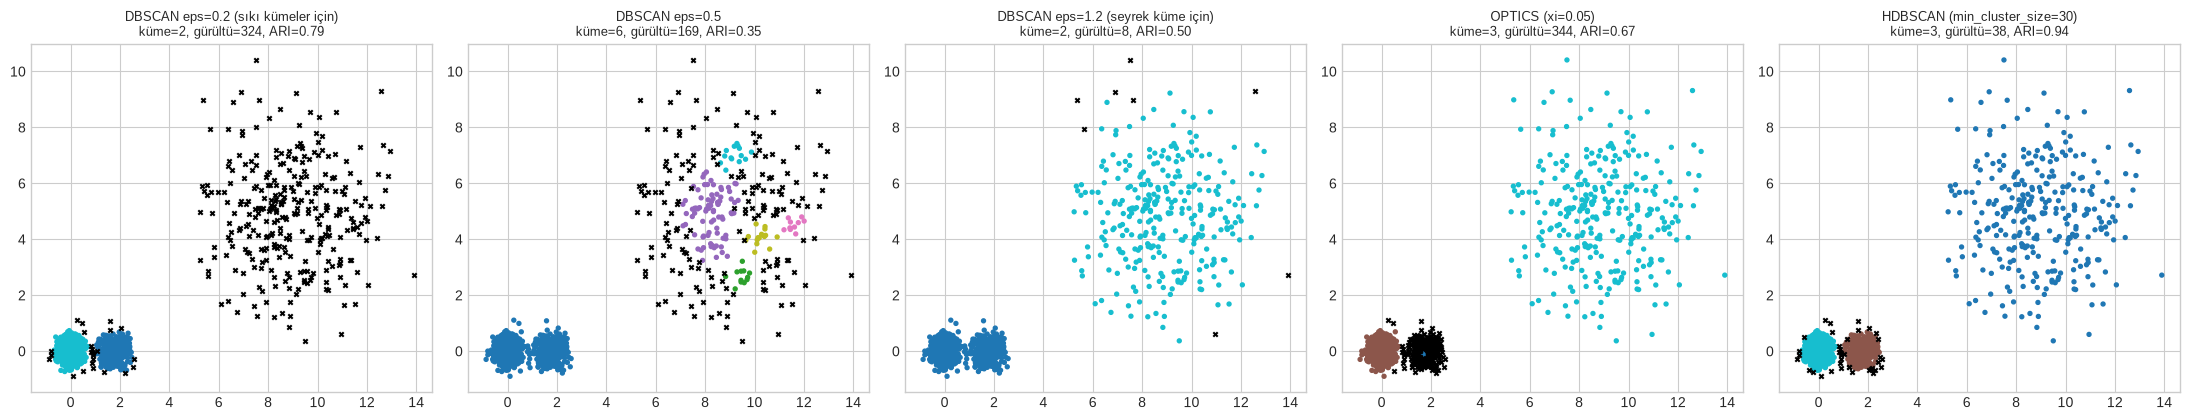

,yöntem,küme,gürültü,ARI
0,DBSCAN eps=0.2 (sıkı kümeler için),2,324,0.785
1,DBSCAN eps=0.5,6,169,0.348
2,DBSCAN eps=1.2 (seyrek küme için),2,8,0.495
3,OPTICS (xi=0.05),3,344,0.672
4,HDBSCAN (min_cluster_size=30),3,38,0.944


In [20]:
X_var, y_var = make_blobs(n_samples=[400, 400, 300], centers=[[0, 0], [1.8, 0], [9, 5]],
                          cluster_std=[0.3, 0.3, 1.8], random_state=3)

def ari_strict(y_true, labels):
    """Gürültü noktalarını (-1) TEK ELEMANLI kendi kümesi sayan ARI (muhafazakâr): 'gürültü' etiketi bir sınıf gibi
    puan toplayamaz."""
    lab = np.array(labels, dtype=int).copy()
    noise = lab == -1
    lab[noise] = lab.max() + 1 + np.arange(noise.sum())
    return adjusted_rand_score(y_true, lab)

configs = [
    ('DBSCAN eps=0.2 (sıkı kümeler için)', DBSCAN(eps=0.2, min_samples=10)),
    ('DBSCAN eps=0.5', DBSCAN(eps=0.5, min_samples=10)),
    ('DBSCAN eps=1.2 (seyrek küme için)', DBSCAN(eps=1.2, min_samples=10)),
    ('OPTICS (xi=0.05)', OPTICS(min_samples=10, xi=0.05, min_cluster_size=50)),
    ('HDBSCAN (min_cluster_size=30)', HDBSCAN(min_cluster_size=30, copy=True) if 'copy' in HDBSCAN().get_params() else HDBSCAN(min_cluster_size=30)),
]

fig, axes = plt.subplots(1, 5, figsize=(22, 4.3))
out_rows = []
for ax, (name, model) in zip(axes, configs):
    lab = model.fit_predict(X_var)
    k = len(set(lab)) - (1 if -1 in lab else 0)
    ari = ari_strict(y_var, lab)
    out_rows.append({'yöntem': name, 'küme': k, 'gürültü': int((lab == -1).sum()), 'ARI': round(ari, 3)})
    ax.scatter(X_var[lab >= 0, 0], X_var[lab >= 0, 1], c=lab[lab >= 0], cmap='tab10', s=8)
    ax.scatter(X_var[lab == -1, 0], X_var[lab == -1, 1], c='k', marker='x', s=10)
    ax.set_title(f'{name}\nküme={k}, gürültü={int((lab == -1).sum())}, ARI={ari:.2f}', fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame(out_rows))

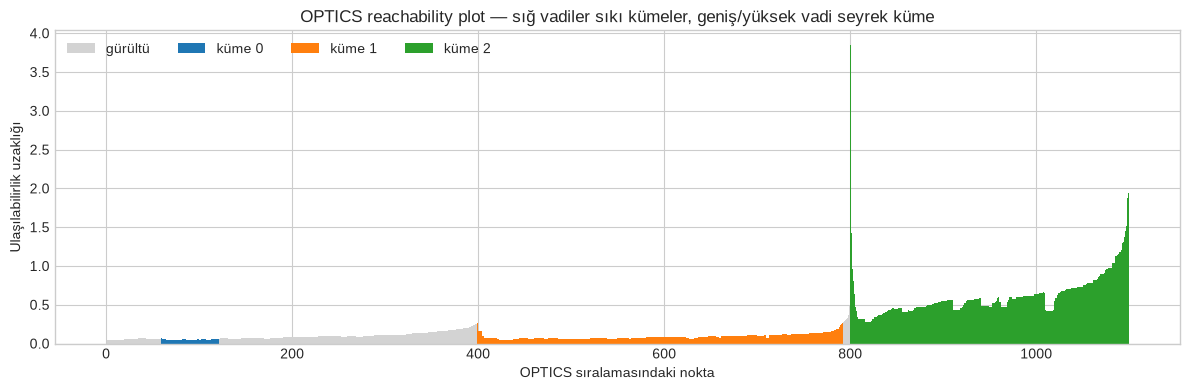

YORUM: Tek bir eps iki ihtiyacı birden karşılayamıyor: eps=0.2'de seyrek küme tümüyle gürültüye düşüyor (324 gürültü),
eps=1.2'de iki sıkı küme tek kümeye birleşiyor (toplam 2 küme). HDBSCAN üç kümeyi de bulup çok az noktayı
dışarıda bırakıyor (ARI=0.944). OPTICS de 3 küme buldu ama sıkı kümelerden birini gürültü olarak işaretledi
(344 gürültü, ARI=0.672) — xi gibi küme-çıkarım parametresine duyarlı. Not: HDBSCAN'de de
min_cluster_size makul seçilmeli; çok büyük seçilirse küçük kümeler gürültüye karışır.


In [21]:
# OPTICS ulaşılabilirlik grafiği: vadiler = kümeler; vadinin DERİNLİĞİ = o kümenin yoğunluğu
opt = OPTICS(min_samples=10, xi=0.05, min_cluster_size=50).fit(X_var)
reach = opt.reachability_[opt.ordering_]
labs_o = opt.labels_[opt.ordering_]

fig, ax = plt.subplots(figsize=(12, 4))
for lab in sorted(set(labs_o)):
    m = labs_o == lab
    ax.bar(np.where(m)[0], np.where(np.isinf(reach[m]), 0, reach[m]), width=1.0,
           color='lightgray' if lab == -1 else plt.get_cmap('tab10')(lab), label='gürültü' if lab == -1 else f'küme {lab}')
ax.set_xlabel('OPTICS sıralamasındaki nokta'); ax.set_ylabel('Ulaşılabilirlik uzaklığı')
ax.set_title('OPTICS reachability plot — sığ vadiler sıkı kümeler, geniş/yüksek vadi seyrek küme')
ax.legend(ncol=4); plt.tight_layout(); plt.show()
res10 = pd.DataFrame(out_rows).set_index('yöntem')
print(f'YORUM: Tek bir eps iki ihtiyacı birden karşılayamıyor: eps=0.2\'de seyrek küme tümüyle gürültüye düşüyor ({int(res10.iloc[0]["gürültü"])} gürültü),')
print(f'eps=1.2\'de iki sıkı küme tek kümeye birleşiyor (toplam {int(res10.iloc[2]["küme"])} küme). HDBSCAN üç kümeyi de bulup çok az noktayı')
print(f'dışarıda bırakıyor (ARI={res10.iloc[4]["ARI"]}). OPTICS de 3 küme buldu ama sıkı kümelerden birini gürültü olarak işaretledi')
print(f'({int(res10.iloc[3]["gürültü"])} gürültü, ARI={res10.iloc[3]["ARI"]}) — xi gibi küme-çıkarım parametresine duyarlı. Not: HDBSCAN\'de de')
print('min_cluster_size makul seçilmeli; çok büyük seçilirse küçük kümeler gürültüye karışır.')

## Adım 11 · `faithful` Verisinin Keşfi ve GMM Sorumluluğunun Elle Hesabı

**Ne yapıyoruz?** **Old Faithful** gayzerinin (Yellowstone, ABD) **272 patlamasını** yüklüyoruz
(Azzalini & Bowman 1990, R `datasets::faithful`): `eruptions` (patlama süresi, dakika) ve
`waiting` (bir önceki patlamadan bu yana geçen bekleme, dakika). İstatistikte iki-modlu (iki
tepeli) dağılımın klasik örneğidir: gayzer ya **kısa patlama + kısa bekleme** ya da **uzun
patlama + uzun bekleme** rejiminde çalışır.

Sonra §4.3'teki **boy örneğini** elle hesaplıyoruz: iki Gauss'un yoğunluklarını `scipy.stats.norm`
ile değerlendirip 170 cm'lik birinin **sorumluluk (responsibility)** değerlerini bulup elle
yaptığımız ($\approx0.41 / 0.59$) sonuçla karşılaştırıyoruz.

faithful: (272, 2) | eksik değer: 0


,eruptions,waiting
count,272.00,272.00
mean,3.49,70.90
std,1.14,13.59
min,1.60,43.00
25%,2.16,58.00
50%,4.00,76.00
75%,4.45,82.00
max,5.10,96.00


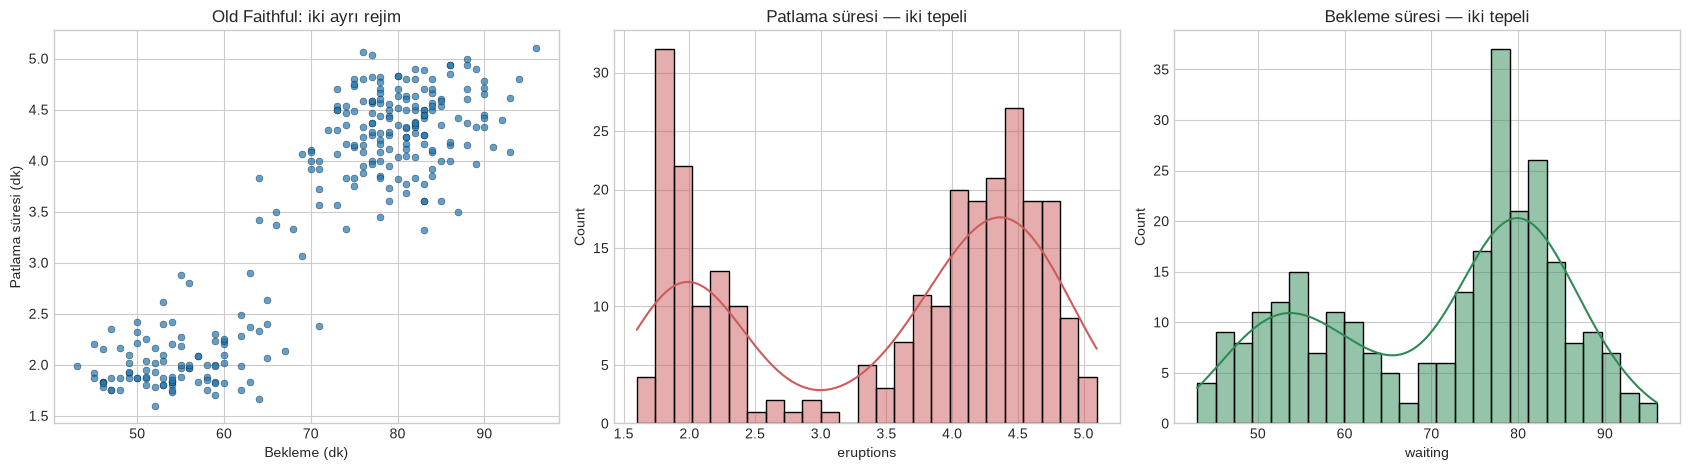

In [22]:
faith = pd.read_csv('data/faithful.csv', index_col=0)
print('faithful:', faith.shape, '| eksik değer:', int(faith.isna().sum().sum()))
display(faith.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(faith['waiting'], faith['eruptions'], s=25, alpha=0.7, edgecolor='k', linewidth=0.3)
axes[0].set_xlabel('Bekleme (dk)'); axes[0].set_ylabel('Patlama süresi (dk)'); axes[0].set_title('Old Faithful: iki ayrı rejim')
sns.histplot(faith['eruptions'], bins=25, kde=True, ax=axes[1], color='indianred'); axes[1].set_title('Patlama süresi — iki tepeli')
sns.histplot(faith['waiting'], bins=25, kde=True, ax=axes[2], color='seagreen'); axes[2].set_title('Bekleme süresi — iki tepeli')
plt.tight_layout(); plt.show()
X_f = faith[['waiting', 'eruptions']].to_numpy()       # (272, 2) — GMM tam kovaryansı ölçek-bağımsızdır, ham veriyle çalışacağız

x=170 cm için çan yükseklikleri : Grup1=0.0273 | Grup2=0.0395  (elle hesap: 0.0273 / 0.0395)
Sorumluluklar (yumuşak atama)         : Grup1=0.409 | Grup2=0.591   (elle hesap: ~0.41 / ~0.59)
  Önsel olasılık Grup1=0.50 -> sorumluluk Grup1=0.409, Grup2=0.591
  Önsel olasılık Grup1=0.80 -> sorumluluk Grup1=0.735, Grup2=0.265
  Önsel olasılık Grup1=0.95 -> sorumluluk Grup1=0.929, Grup2=0.071


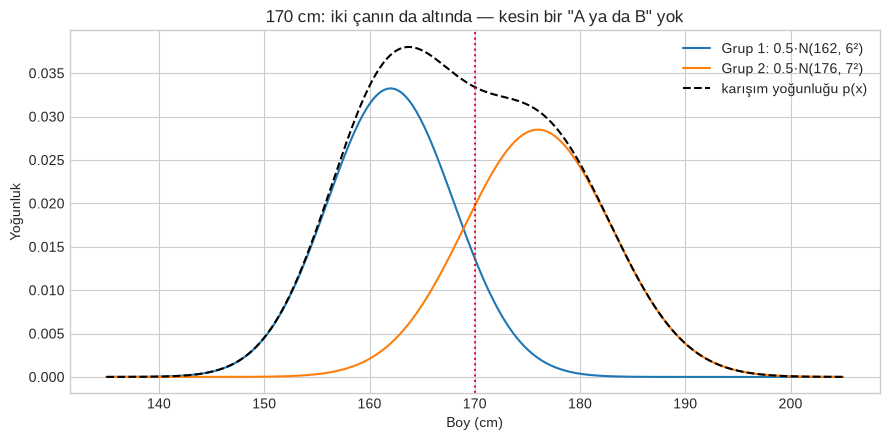


YORUM: Önsel ağırlıklar da sonucu değiştirir: salonun %95'i Grup 1 olsaydı 170 cm'lik biri büyük olasılıkla
Grup 1 sayılırdı. GMM bu yüzden "sadece uzaklık" değil, "uzaklık x grubun ne kadar yaygın olduğu" bilgisini kullanır.


In [23]:
# --- §4.3 elle örnek: iki Gauss, eşit ağırlık, x=170 cm ---
w = np.array([0.5, 0.5]); mu = np.array([162.0, 176.0]); sd = np.array([6.0, 7.0])
x0 = 170.0

pdf = norm.pdf(x0, loc=mu, scale=sd)             # her çanın x0'daki yüksekliği
num = w * pdf                                    # pay: ağırlık x yoğunluk
resp = num / num.sum()                           # payda: toplam -> olasılık

print(f'x={x0:.0f} cm için çan yükseklikleri : Grup1={pdf[0]:.4f} | Grup2={pdf[1]:.4f}  (elle hesap: 0.0273 / 0.0395)')
print(f'Sorumluluklar (yumuşak atama)         : Grup1={resp[0]:.3f} | Grup2={resp[1]:.3f}   (elle hesap: ~0.41 / ~0.59)')

# Ağırlıklar eşit değilse sonuç nasıl değişir? (salonun %80\'i Grup 1 ise)
for w1 in [0.5, 0.8, 0.95]:
    ww = np.array([w1, 1 - w1]); r = ww * pdf / (ww * pdf).sum()
    print(f'  Önsel olasılık Grup1={w1:.2f} -> sorumluluk Grup1={r[0]:.3f}, Grup2={r[1]:.3f}')

xs = np.linspace(135, 205, 400)
plt.figure(figsize=(9, 4.5))
plt.plot(xs, w[0] * norm.pdf(xs, mu[0], sd[0]), label='Grup 1: 0.5·N(162, 6²)')
plt.plot(xs, w[1] * norm.pdf(xs, mu[1], sd[1]), label='Grup 2: 0.5·N(176, 7²)')
plt.plot(xs, (w[0] * norm.pdf(xs, mu[0], sd[0]) + w[1] * norm.pdf(xs, mu[1], sd[1])), 'k--', label='karışım yoğunluğu p(x)')
plt.axvline(x0, color='crimson', ls=':'); plt.xlabel('Boy (cm)'); plt.ylabel('Yoğunluk'); plt.legend()
plt.title('170 cm: iki çanın da altında — kesin bir "A ya da B" yok')
plt.tight_layout(); plt.show()
print('\nYORUM: Önsel ağırlıklar da sonucu değiştirir: salonun %95\'i Grup 1 olsaydı 170 cm\'lik biri büyük olasılıkla')
print('Grup 1 sayılırdı. GMM bu yüzden "sadece uzaklık" değil, "uzaklık x grubun ne kadar yaygın olduğu" bilgisini kullanır.')

## Adım 12 · EM Algoritmasının Sıfırdan Implementasyonu ve `GaussianMixture` ile Doğrulama

**Ne yapıyoruz?** §4.4'teki EM döngüsünü `SimpleGMM` sınıfıyla kodluyoruz:

1. **Başlatma:** K-Means ile sert atama → ilk $\pi_j,\mu_j,\Sigma_j$ (scikit-learn de bunu varsayılan yapar).
2. **E-adımı:** sorumluluk matrisi $r_{ij}$ (sayısal kararlılık için **log uzayında**: $\log\sum\exp$).
3. **M-adımı:** ağırlıklı ortalama / ağırlıklı kovaryans, köşegene küçük `reg_covar` eklenir (tekillik koruması, §4.7).
4. **Durma:** log-olabilirlik artışı eşikten küçükse.

Sonra aynı başlatma ve çok sıkı yakınsama eşiğiyle `sklearn.mixture.GaussianMixture`'ı
çalıştırıp **parametreleri ve log-olabilirliği** karşılaştırıyoruz; ayrıca EM'in log-olabilirliği
**her iterasyonda artırdığını** (§4.4'teki garanti) doğruluyoruz.

In [24]:
from scipy.special import logsumexp
from matplotlib.patches import Ellipse

class SimpleGMM:
    """Tam kovaryanslı GMM, EM ile (sıfırdan)."""

    def __init__(self, n_components=2, max_iter=1000, tol=1e-8, reg_covar=1e-6, random_state=42):
        self.K, self.max_iter, self.tol, self.reg_covar, self.random_state = n_components, max_iter, tol, reg_covar, random_state

    def _m_step(self, X, resp):
        n, d = X.shape
        Nk = resp.sum(axis=0) + 10 * np.finfo(float).eps          # N_j = Σ_i r_ij
        self.weights_ = Nk / n                                    # π_j
        self.means_ = (resp.T @ X) / Nk[:, None]                  # μ_j: sorumluluk-ağırlıklı ortalama
        self.covs_ = np.empty((self.K, d, d))
        for j in range(self.K):
            diff = X - self.means_[j]
            self.covs_[j] = (resp[:, j, None] * diff).T @ diff / Nk[j] + self.reg_covar * np.eye(d)   # Σ_j

    def _log_resp(self, X):
        # log(π_j N(x|μ_j,Σ_j)) matrisi, sonra satır-bazlı normalizasyon -> log r_ij
        log_prob = np.column_stack([np.log(self.weights_[j]) + multivariate_normal(self.means_[j], self.covs_[j]).logpdf(X)
                                    for j in range(self.K)])
        log_norm = logsumexp(log_prob, axis=1)                    # log p(x_i)
        return log_prob - log_norm[:, None], log_norm.mean()

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rs = np.random.RandomState(self.random_state)
        km = KMeans(n_clusters=self.K, n_init=1, random_state=rs).fit(X)   # 1) başlatma
        resp = np.eye(self.K)[km.labels_]
        self._m_step(X, resp)
        self.history_ = [(self.weights_.copy(), self.means_.copy(), self.covs_.copy())]
        self.ll_history_, prev = [], -np.inf
        for it in range(self.max_iter):
            log_resp, ll = self._log_resp(X)                      # 2) E-adımı
            self._m_step(X, np.exp(log_resp))                     # 3) M-adımı
            self.history_.append((self.weights_.copy(), self.means_.copy(), self.covs_.copy()))
            self.ll_history_.append(ll)
            if abs(ll - prev) < self.tol:                         # 4) yakınsama
                break
            prev = ll
        self.n_iter_ = it + 1
        return self

    def predict_proba(self, X):
        return np.exp(self._log_resp(np.asarray(X, float))[0])

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def score(self, X):
        return self._log_resp(np.asarray(X, float))[1]            # ortalama log-olabilirlik

print('SimpleGMM tanımlandı.')

SimpleGMM tanımlandı.


In [25]:
my_gmm = SimpleGMM(n_components=2, random_state=42).fit(X_f)
sk_gmm = GaussianMixture(n_components=2, covariance_type='full', tol=1e-8, max_iter=1000,
                         n_init=1, random_state=42).fit(X_f)

# Bileşen sırası farklı olabilir: ortalamaya göre hizala
o_my = np.argsort(my_gmm.means_[:, 0]); o_sk = np.argsort(sk_gmm.means_[:, 0])
print(f'Sıfırdan EM iterasyon sayısı: {my_gmm.n_iter_} | sklearn: {sk_gmm.n_iter_}')
print('\nAğırlıklar (π)  sıfırdan:', my_gmm.weights_[o_my].round(4), '| sklearn:', sk_gmm.weights_[o_sk].round(4))
print('Ortalamalar (μ) sıfırdan:\n', my_gmm.means_[o_my].round(3), '\n               sklearn:\n', sk_gmm.means_[o_sk].round(3))
print('\nmax |fark| ağırlık    :', np.abs(my_gmm.weights_[o_my] - sk_gmm.weights_[o_sk]).max())
print('max |fark| ortalama   :', np.abs(my_gmm.means_[o_my] - sk_gmm.means_[o_sk]).max())
print('max |fark| kovaryans  :', np.abs(my_gmm.covs_[o_my] - sk_gmm.covariances_[o_sk]).max())
print(f'Ortalama log-olabilirlik sıfırdan={my_gmm.score(X_f):.6f} | sklearn={sk_gmm.score(X_f):.6f}')

mono = np.all(np.diff(my_gmm.ll_history_) >= -1e-10)
print('\nEM her iterasyonda log-olabilirliği artırıyor mu (monoton)?', mono)
print('Etiket uyumu (ARI, sıfırdan vs sklearn):', adjusted_rand_score(my_gmm.predict(X_f), sk_gmm.predict(X_f)))

Sıfırdan EM iterasyon sayısı: 8 | sklearn: 8

Ağırlıklar (π)  sıfırdan: [0.3559 0.6441] | sklearn: [0.3559 0.6441]
Ortalamalar (μ) sıfırdan:
 [[54.479  2.036]
 [79.968  4.29 ]] 
               sklearn:
 [[54.479  2.036]
 [79.968  4.29 ]]

max |fark| ağırlık    : 1.1102230246251565e-16
max |fark| ortalama   : 0.0
max |fark| kovaryans  : 5.551115123125783e-17
Ortalama log-olabilirlik sıfırdan=-4.155382 | sklearn=-4.155382

EM her iterasyonda log-olabilirliği artırıyor mu (monoton)? True
Etiket uyumu (ARI, sıfırdan vs sklearn): 1.0


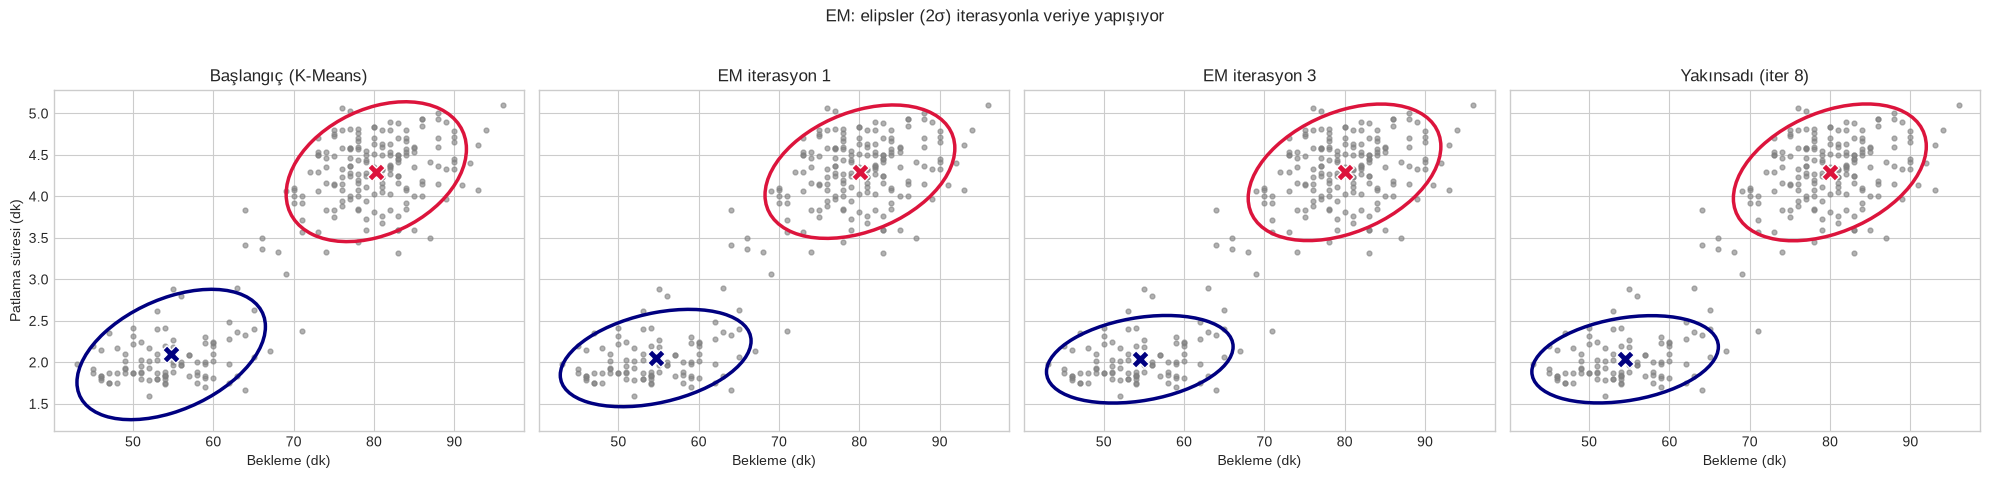

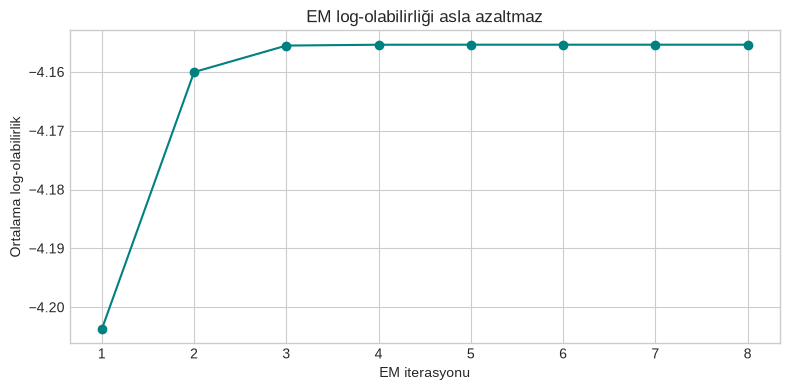

In [26]:
def draw_ellipses(ax, weights, means, covs, n_std=2, colors=('crimson', 'navy', 'darkgreen', 'purple')):
    for j, (m, C) in enumerate(zip(means, covs)):
        vals, vecs = np.linalg.eigh(C)
        order = vals.argsort()[::-1]; vals, vecs = vals[order], vecs[:, order]
        angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
        ax.add_patch(Ellipse(m, 2 * n_std * np.sqrt(vals[0]), 2 * n_std * np.sqrt(vals[1]), angle=angle,
                             fill=False, color=colors[j % len(colors)], lw=2.5))
        ax.scatter(*m, marker='X', s=160, color=colors[j % len(colors)], edgecolor='w', zorder=5)

snap = [0, 1, 3, len(my_gmm.history_) - 1]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharex=True, sharey=True)
for ax, s in zip(axes, snap):
    ax.scatter(X_f[:, 0], X_f[:, 1], s=12, color='gray', alpha=0.6)
    draw_ellipses(ax, *my_gmm.history_[s])
    ax.set_title('Başlangıç (K-Means)' if s == 0 else (f'EM iterasyon {s}' if s != snap[-1] else f'Yakınsadı (iter {s})'))
    ax.set_xlabel('Bekleme (dk)')
axes[0].set_ylabel('Patlama süresi (dk)')
plt.suptitle('EM: elipsler (2σ) iterasyonla veriye yapışıyor', y=1.03); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(my_gmm.ll_history_) + 1), my_gmm.ll_history_, 'o-', color='teal')
ax.set_xlabel('EM iterasyonu'); ax.set_ylabel('Ortalama log-olabilirlik'); ax.set_title('EM log-olabilirliği asla azaltmaz')
plt.tight_layout(); plt.show()

## Adım 13 · Yumuşak Atama: Belirsiz Noktalar ve K-Means ile Karşılaştırma

**Ne yapıyoruz?** GMM'in en pratik katkısı: **her nokta için olasılık**. `predict_proba` ile
iki kümenin ortasında kalan, atamadan **emin olunmayan** noktaları buluyoruz ve K-Means'in
**sert** etiketiyle karşılaştırıyoruz. Ek olarak GMM'in **ölçekten bağımsız** olduğunu görüyoruz:
tam kovaryanslı GMM'in sonucu, değişkenleri farklı birimlerle ölçsek de **değişmez** (kovaryans
matrisi birim farkını kendisi öğrenir); K-Means ise ölçeğe duyarlı.

Toplam 272 patlama | atama olasılığı < 0.90 olan "belirsiz" nokta sayısı: 1 (%0.4)
Atama olasılığı yüzdelikleri (en yüksek bileşen olasılığı): [0.994 1.    1.    1.   ]


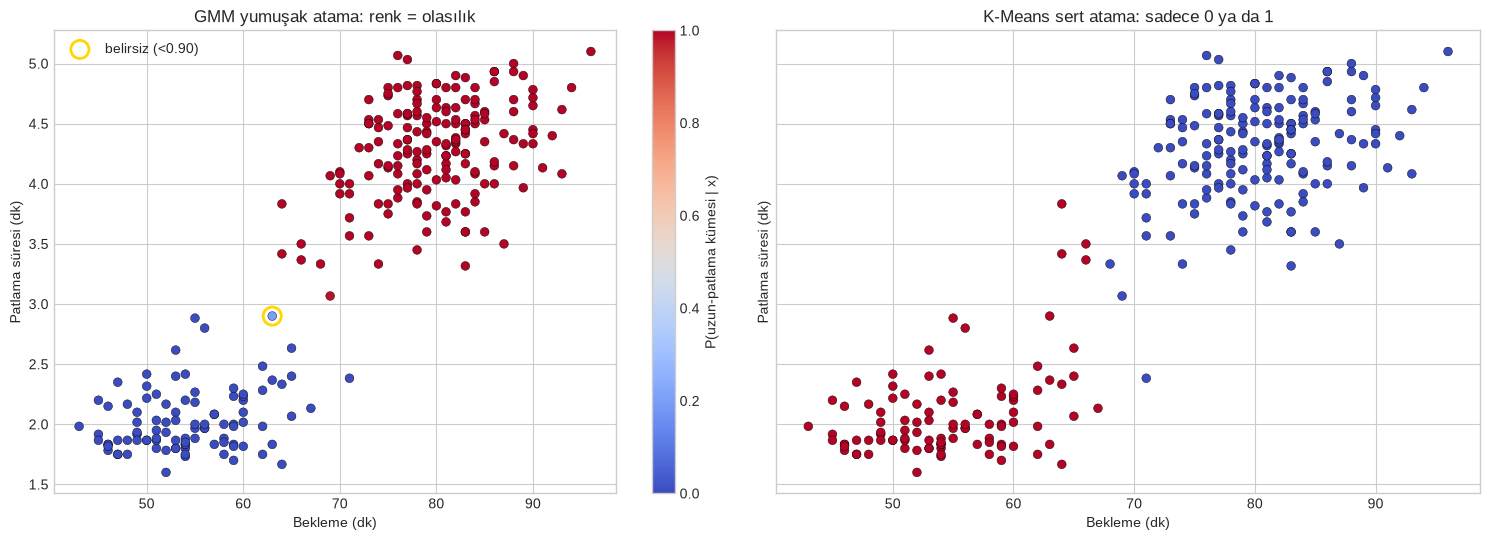

GMM sert etiket vs K-Means etiket ARI = 0.927

YORUM: Old Faithful'ın iki rejimi iyi ayrık: noktaların %95'i en az %100.0 güvenle atanıyor, belirsiz sadece
1 nokta var (E6'da eşiği yükselterek sayıyı artıracaksın). Yumuşak atamanın asıl değeri kümelerin ÇAKIŞTIĞI veride —
bir sonraki hücrede bunu somut görüyoruz.


In [27]:
proba = sk_gmm.predict_proba(X_f)
conf = proba.max(axis=1)
uncertain = conf < 0.90
print(f'Toplam {len(X_f)} patlama | atama olasılığı < 0.90 olan "belirsiz" nokta sayısı: {int(uncertain.sum())} (%{100*uncertain.mean():.1f})')
print('Atama olasılığı yüzdelikleri (en yüksek bileşen olasılığı):', np.percentile(conf, [1, 5, 25, 50]).round(3))

# P(uzun-rejim | x) — hangi bileşenin "uzun patlama" olduğunu ortalamadan bul
long_comp = int(np.argmax(sk_gmm.means_[:, 1]))
p_long = proba[:, long_comp]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True, sharey=True)
sc = axes[0].scatter(X_f[:, 0], X_f[:, 1], c=p_long, cmap='coolwarm', s=40, edgecolor='k', linewidth=0.3)
plt.colorbar(sc, ax=axes[0], label='P(uzun-patlama kümesi | x)')
axes[0].scatter(X_f[uncertain, 0], X_f[uncertain, 1], facecolors='none', edgecolors='gold', s=170, linewidth=2, label='belirsiz (<0.90)')
axes[0].legend(); axes[0].set_title('GMM yumuşak atama: renk = olasılık')
km_f = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_f)
axes[1].scatter(X_f[:, 0], X_f[:, 1], c=km_f.labels_, cmap='coolwarm', s=40, edgecolor='k', linewidth=0.3)
axes[1].set_title('K-Means sert atama: sadece 0 ya da 1')
for ax in axes: ax.set_xlabel('Bekleme (dk)'); ax.set_ylabel('Patlama süresi (dk)')
plt.tight_layout(); plt.show()

print('GMM sert etiket vs K-Means etiket ARI =', round(adjusted_rand_score(sk_gmm.predict(X_f), km_f.labels_), 3))
print(f'\nYORUM: Old Faithful\'ın iki rejimi iyi ayrık: noktaların %95\'i en az %{100*np.percentile(conf, 5):.1f} güvenle atanıyor, belirsiz sadece')
print(f'{int(uncertain.sum())} nokta var (E6\'da eşiği yükselterek sayıyı artıracaksın). Yumuşak atamanın asıl değeri kümelerin ÇAKIŞTIĞI veride —')
print('bir sonraki hücrede bunu somut görüyoruz.')

Çakışan iki küme (600 nokta): atama olasılığı < 0.90 olan nokta sayısı = 201 (%34)
Aynı veride K-Means sert etiketleri: ARI(K-Means, gerçek) = 0.557 | ARI(GMM, gerçek) = 0.547


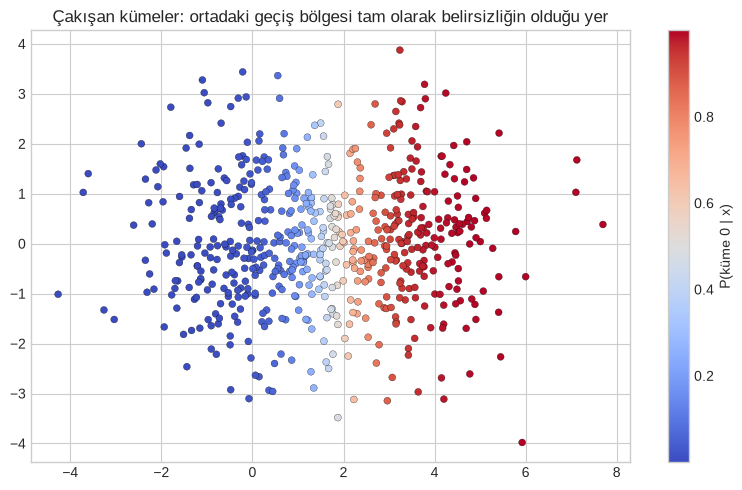

YORUM: Kümeler çakışınca ortadaki nokta kümesi belirsiz kalıyor; GMM bu noktalara "%55 / %45" gibi dürüst bir cevap
veriyor, K-Means ise aynı noktalara sert bir etiket yapıştırıp belirsizliği saklıyor. Churn/risk skorlaması gibi
uygulamalarda "ne kadar emin olduğumuz" doğrudan iş kararının girdisidir.
Birim değiştirince (patlama süresi dk -> sn) etiketlerin değişmesi, ARI (1 = hiç değişmedi):
  GMM (full)  : ARI = 1.000
  K-Means     : ARI = 0.913

YORUM: Tam kovaryanslı GMM birim değişimine duyarsız (kovaryans matrisi ölçeği kendisi öğreniyor); K-Means ise
uzaklığı doğrudan kullandığı için bir değişkenin birimi değişince bazı noktalar kümelerini değiştirebilir —
bu yüzden K-Means öncesi ölçekleme şart (01 · Veri Ön İşleme), GMM(full) için şart değildir.


In [28]:
# --- Çakışan kümeler: yumuşak atamanın asıl değeri ---
X_ov, y_ov = make_blobs(n_samples=600, centers=[[0, 0], [3, 0]], cluster_std=1.3, random_state=5)
gm_ov = GaussianMixture(2, covariance_type='full', n_init=5, random_state=42).fit(X_ov)
conf_ov = gm_ov.predict_proba(X_ov).max(axis=1)
print(f'Çakışan iki küme (600 nokta): atama olasılığı < 0.90 olan nokta sayısı = {int((conf_ov < 0.90).sum())} (%{100*(conf_ov < 0.90).mean():.0f})')
km_ov = KMeans(2, n_init=10, random_state=42).fit(X_ov)
print(f'Aynı veride K-Means sert etiketleri: ARI(K-Means, gerçek) = {adjusted_rand_score(y_ov, km_ov.labels_):.3f} | '
      f'ARI(GMM, gerçek) = {adjusted_rand_score(y_ov, gm_ov.predict(X_ov)):.3f}')

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(X_ov[:, 0], X_ov[:, 1], c=gm_ov.predict_proba(X_ov)[:, 0], cmap='coolwarm', s=25, edgecolor='k', linewidth=0.2)
plt.colorbar(sc, label='P(küme 0 | x)'); ax.set_title('Çakışan kümeler: ortadaki geçiş bölgesi tam olarak belirsizliğin olduğu yer')
plt.tight_layout(); plt.show()
print('YORUM: Kümeler çakışınca ortadaki nokta kümesi belirsiz kalıyor; GMM bu noktalara "%55 / %45" gibi dürüst bir cevap')
print('veriyor, K-Means ise aynı noktalara sert bir etiket yapıştırıp belirsizliği saklıyor. Churn/risk skorlaması gibi')
print('uygulamalarda "ne kadar emin olduğumuz" doğrudan iş kararının girdisidir.')

# Ölçek bağımsızlığı: patlama süresini DAKİKA yerine SANİYE olarak verelim (x60)
X_f_sec = X_f * np.array([1.0, 60.0])        # waiting dk, eruptions sn

gmm_raw = GaussianMixture(2, covariance_type='full', n_init=5, random_state=42).fit(X_f)
gmm_sec = GaussianMixture(2, covariance_type='full', n_init=5, random_state=42).fit(X_f_sec)
km_raw = KMeans(2, n_init=10, random_state=42).fit(X_f)
km_sec = KMeans(2, n_init=10, random_state=42).fit(X_f_sec)

print('Birim değiştirince (patlama süresi dk -> sn) etiketlerin değişmesi, ARI (1 = hiç değişmedi):')
print(f'  GMM (full)  : ARI = {adjusted_rand_score(gmm_raw.predict(X_f), gmm_sec.predict(X_f_sec)):.3f}')
print(f'  K-Means     : ARI = {adjusted_rand_score(km_raw.predict(X_f), km_sec.predict(X_f_sec)):.3f}')
print('\nYORUM: Tam kovaryanslı GMM birim değişimine duyarsız (kovaryans matrisi ölçeği kendisi öğreniyor); K-Means ise')
print('uzaklığı doğrudan kullandığı için bir değişkenin birimi değişince bazı noktalar kümelerini değiştirebilir —')
print('bu yüzden K-Means öncesi ölçekleme şart (01 · Veri Ön İşleme), GMM(full) için şart değildir.')

## Adım 14 · Kovaryans Türü × Bileşen Sayısı: BIC / AIC ile Model Seçimi

**Ne yapıyoruz?** §4.5-4.6'daki iki tasarım kararını (kaç bileşen? hangi kovaryans türü?) **BIC
ve AIC** ile veriye bırakıyoruz: $K=1,\dots,6$ ve 4 kovaryans türü için 24 model eğitip (her
biri `n_init=5`) BIC/AIC çiziyoruz. **En düşük değer en iyidir.** Yorum: modelin veriyi iyi
açıklaması ve gereksiz karmaşık olmaması arasındaki denge.

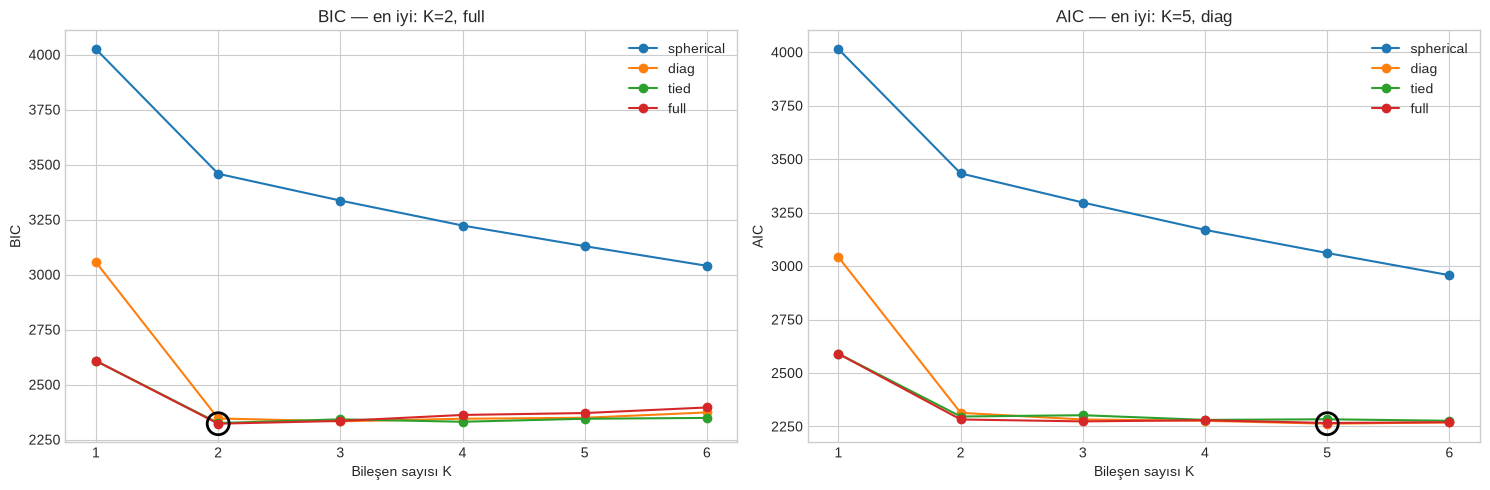

En düşük BIC: K=2, covariance_type=full  (BIC=2322.2, serbest parametre=13)
En düşük AIC: K=5, covariance_type=diag  (AIC=2262.7, serbest parametre=24)


cov,diag,full,spherical,tied
K,,,,
1,3055.8,2607.6,4024.7,2607.6
2,2346.1,2322.2,3458.3,2325.2
3,2333.0,2334.9,3336.6,2342.1
4,2344.9,2362.0,3223.2,2331.1
5,2349.3,2370.7,3129.3,2344.8
6,2373.5,2396.0,3040.0,2348.5


BIC'e göre en iyi 3 model: [('full', 2, 2322.2), ('tied', 2, 2325.2), ('tied', 4, 2331.1)]
YORUM: BIC, gözle gördüğümüz iki rejimi doğruluyor (K=2, full). AIC ise daha hafif ceza
verdiği için daha fazla bileşen seçti (K=5, diag) — aynı veride iki ölçüt farklı sonuç verebilir;
BIC büyük n'de daha tutucu. Ayrıca en iyi 3 modelin BIC farkı küçükse (~10 puan altı) bunları "eşdeğer" saymak gerekir —
tek bir sayıya değil, makul adaylar kümesine bakmak daha sağlıklı.


In [29]:
cov_types = ['spherical', 'diag', 'tied', 'full']
K_range = range(1, 7)
rows = []
for ct in cov_types:
    for K in K_range:
        g = GaussianMixture(n_components=K, covariance_type=ct, n_init=5, random_state=42).fit(X_f)
        rows.append({'cov': ct, 'K': K, 'BIC': g.bic(X_f), 'AIC': g.aic(X_f), 'param': sum(p.size for p in
                     [g.weights_, g.means_, g.covariances_]) - 1})
ic = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, metric in zip(axes, ['BIC', 'AIC']):
    for ct in cov_types:
        sub = ic[ic['cov'] == ct]
        ax.plot(sub['K'], sub[metric], 'o-', label=ct)
    best = ic.loc[ic[metric].idxmin()]
    ax.scatter(best['K'], best[metric], s=250, facecolors='none', edgecolors='k', linewidth=2, zorder=5)
    ax.set_title(f'{metric} — en iyi: K={int(best["K"])}, {best["cov"]}'); ax.set_xlabel('Bileşen sayısı K'); ax.set_ylabel(metric); ax.legend()
plt.tight_layout(); plt.show()

best_bic = ic.loc[ic['BIC'].idxmin()]; best_aic = ic.loc[ic['AIC'].idxmin()]
print(f'En düşük BIC: K={int(best_bic["K"])}, covariance_type={best_bic["cov"]}  (BIC={best_bic["BIC"]:.1f}, serbest parametre={int(best_bic["param"])})')
print(f'En düşük AIC: K={int(best_aic["K"])}, covariance_type={best_aic["cov"]}  (AIC={best_aic["AIC"]:.1f}, serbest parametre={int(best_aic["param"])})')
display(ic.pivot(index='K', columns='cov', values='BIC').round(1))
bic_sorted = ic.sort_values('BIC').head(3)
print('BIC\'e göre en iyi 3 model:', [(r['cov'], int(r['K']), round(r['BIC'], 1)) for _, r in bic_sorted.iterrows()])
print(f'YORUM: BIC, gözle gördüğümüz iki rejimi doğruluyor (K={int(best_bic["K"])}, {best_bic["cov"]}). AIC ise daha hafif ceza')
print(f'verdiği için daha fazla bileşen seçti (K={int(best_aic["K"])}, {best_aic["cov"]}) — aynı veride iki ölçüt farklı sonuç verebilir;')
print('BIC büyük n\'de daha tutucu. Ayrıca en iyi 3 modelin BIC farkı küçükse (~10 puan altı) bunları "eşdeğer" saymak gerekir —')
print('tek bir sayıya değil, makul adaylar kümesine bakmak daha sağlıklı.')

## Adım 15 · GMM vs K-Means (Eğik Elips Kümeler) ve GMM'in Üretken (Generative) Yönü

**Ne yapıyoruz?** İki şey:

1. **Eğik elips kümelerde GMM'in avantajı:** Adım 4'te kullandığımız eğik/uzamış 3 kümeli
   sentetik veride K-Means ile `full` kovaryanslı GMM'i **ARI** ile karşılaştırıyoruz.
2. **GMM bir yoğunluk modelidir:** (a) `sample()` ile modelden **yeni sentetik gözlem üretiyoruz**,
   (b) `score_samples()` ile her noktanın **log-olabilirliğini** hesaplayıp bu skoru **anomali
   tespiti** için kullanıyoruz (modele göre çok düşük olasılıklı = şüpheli).

K-Means                  ARI = 0.550
GMM (spherical = K-Means'e benzer) ARI = 0.526
GMM (full)               ARI = 1.000


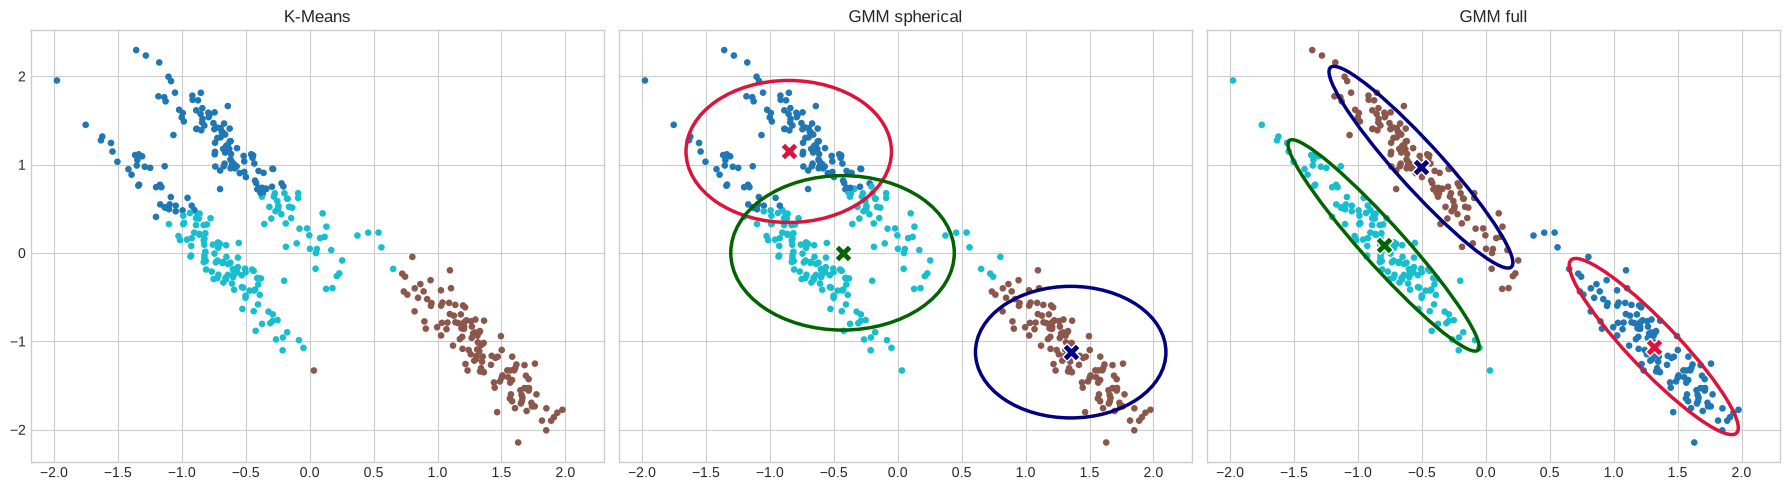

In [30]:
X_an, y_an = shapes['eğik elips kümeler']
X_an_sc = StandardScaler().fit_transform(X_an)

km_an = KMeans(3, n_init=10, random_state=42).fit(X_an_sc)
gm_an = GaussianMixture(3, covariance_type='full', n_init=5, random_state=42).fit(X_an_sc)
gm_sph = GaussianMixture(3, covariance_type='spherical', n_init=5, random_state=42).fit(X_an_sc)

print(f'K-Means                  ARI = {adjusted_rand_score(y_an, km_an.labels_):.3f}')
print(f'GMM (spherical = K-Means\'e benzer) ARI = {adjusted_rand_score(y_an, gm_sph.predict(X_an_sc)):.3f}')
print(f'GMM (full)               ARI = {adjusted_rand_score(y_an, gm_an.predict(X_an_sc)):.3f}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (title, lab, model) in zip(axes, [('K-Means', km_an.labels_, None), ('GMM spherical', gm_sph.predict(X_an_sc), gm_sph),
                                           ('GMM full', gm_an.predict(X_an_sc), gm_an)]):
    ax.scatter(X_an_sc[:, 0], X_an_sc[:, 1], c=lab, cmap='tab10', s=14)
    if model is not None:
        covs = model.covariances_
        if model.covariance_type == 'spherical':
            covs = np.array([np.eye(2) * c for c in covs])
        draw_ellipses(ax, model.weights_, model.means_, covs)
    ax.set_title(title)
plt.tight_layout(); plt.show()

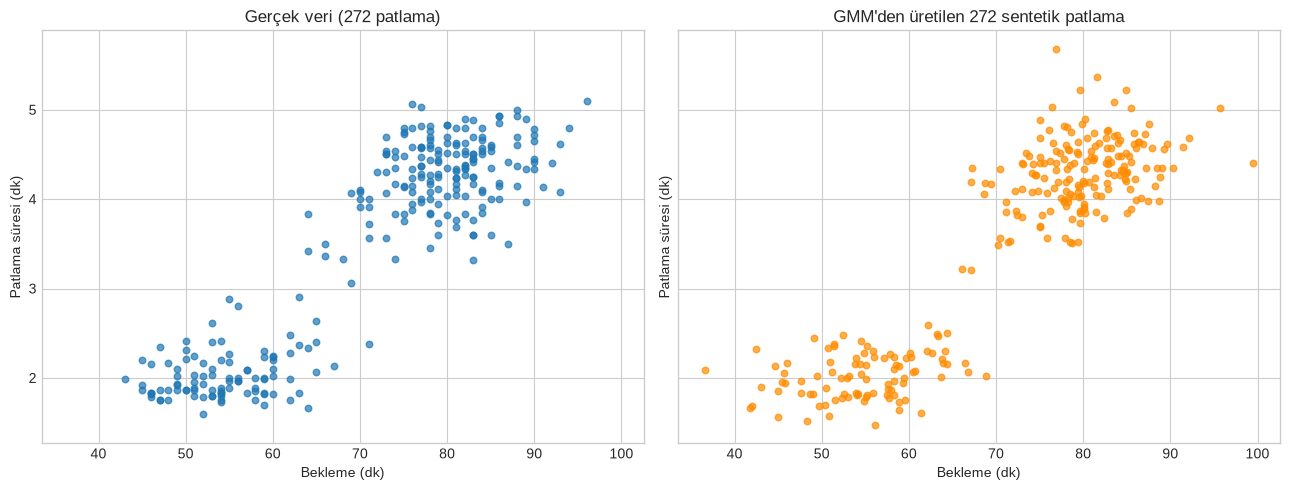

Eşik (eğitim log-olabilirliğinin %1 yüzdeliği): -7.68


,bekleme,patlama,log-olabilirlik,anomali mi? (< %1 eşiği)
0,55.0,4.8,-16.39,True
1,90.0,1.7,-26.94,True
2,75.0,3.0,-8.07,True
3,53.0,1.9,-3.39,False
4,80.0,4.4,-3.15,False


YORUM: Modele göre düşük olasılıklı, rejimlerin ikisine de benzemeyen noktalar anomali sayılıyor; tipik kısa/uzun
rejim noktaları normal çıkıyor. Bu, GMM'in "küme" bulmanın ötesinde bir yoğunluk modeli olduğunu gösteriyor (bkz. 19 · Anomali Tespiti).


In [31]:
# --- GMM üretken model: yeni gayzer patlaması üret ---
X_new, comp_new = sk_gmm.sample(272)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
axes[0].scatter(X_f[:, 0], X_f[:, 1], s=22, alpha=0.7); axes[0].set_title('Gerçek veri (272 patlama)')
axes[1].scatter(X_new[:, 0], X_new[:, 1], s=22, alpha=0.7, color='darkorange'); axes[1].set_title('GMM\'den üretilen 272 sentetik patlama')
for ax in axes: ax.set_xlabel('Bekleme (dk)'); ax.set_ylabel('Patlama süresi (dk)')
plt.tight_layout(); plt.show()

# --- Anomali tespiti: log-olabilirlik eşiği ---
ll_train = sk_gmm.score_samples(X_f)
thr = np.percentile(ll_train, 1)           # eğitim verisinin en düşük %1'i eşik
suspects = np.array([[55.0, 4.8],          # kısa bekleme ama çok uzun patlama (rejimlerin ikisine de uymuyor)
                     [90.0, 1.7],          # uzun bekleme ama çok kısa patlama
                     [75.0, 3.0],          # iki rejimin ortası
                     [53.0, 1.9],          # normal "kısa" rejim noktası
                     [80.0, 4.4]])         # normal "uzun" rejim noktası
ll_s = sk_gmm.score_samples(suspects)
out = pd.DataFrame({'bekleme': suspects[:, 0], 'patlama': suspects[:, 1], 'log-olabilirlik': ll_s.round(2),
                    'anomali mi? (< %1 eşiği)': ll_s < thr})
print(f'Eşik (eğitim log-olabilirliğinin %1 yüzdeliği): {thr:.2f}')
display(out)
print('YORUM: Modele göre düşük olasılıklı, rejimlerin ikisine de benzemeyen noktalar anomali sayılıyor; tipik kısa/uzun')
print('rejim noktaları normal çıkıyor. Bu, GMM\'in "küme" bulmanın ötesinde bir yoğunluk modeli olduğunu gösteriyor (bkz. 19 · Anomali Tespiti).')

## Adım 16 · Sentez: 5 Yöntem × 5 Veri Şekli ve Kümeleme Metrikleri

**Ne yapıyoruz?** Notebook'un tüm yöntemlerini (+ 16'dan K-Means) **aynı 5 veri şeklinde**
karşılaştırıyoruz: 3 yuvarlak küme, iki hilal, iç içe halkalar, eğik elips kümeler ve
**farklı yoğunluklu** kümeler. Her yöntem **gerçek $k$** ile ($k$ gerektiren yöntemlere) veya
**otomatik bir kuralla** ($\varepsilon$ = 5-uzaklığın %90'lık yüzdeliği, DBSCAN için) çalıştırılıyor,
tek tek ayar yapılmıyor — amaç "her yöntemin doğal güçlü ve zayıf olduğu yeri" görmek. Ardından
§5'teki **iç metrikleri** (silhouette, Davies-Bouldin, Calinski-Harabasz) hilal verisinde
hesaplayıp **metriğin yanıltabileceğini** gösteriyoruz.

,K-Means,Ward,Single,DBSCAN,HDBSCAN,GMM (full)
3 yuvarlak küme,1.00,1.00,1.00,0.91,1.00,1.00
iki hilal,0.47,0.48,1.00,0.88,0.96,0.47
iç içe halkalar,-0.00,-0.00,1.00,0.59,0.99,-0.00
eğik elips kümeler,0.55,0.52,0.57,0.92,0.72,1.00
farklı yoğunluklu,0.42,0.44,0.50,0.40,0.93,0.42


Her şekilde (en yüksek ARI'ya 0.02 içinde) öne çıkan yöntemler:
  3 yuvarlak küme     : K-Means, Ward, Single, HDBSCAN, GMM (full)
  iki hilal           : Single
  iç içe halkalar     : Single, HDBSCAN
  eğik elips kümeler  : GMM (full)
  farklı yoğunluklu   : HDBSCAN
YORUM: Hiçbir yöntem her şekilde kazanmıyor — K-Means/Ward/GMM kompakt kümelerde, Single/HDBSCAN şekilli kümelerde (otomatik eps ile DBSCAN bu kadar başarılı değil),
GMM(full) eğik elipslerde, HDBSCAN farklı yoğunlukta öne çıkıyor. Doğru yöntem, verinin geometrisine (ve gürültü/olasılık ihtiyacına) göre seçilir.


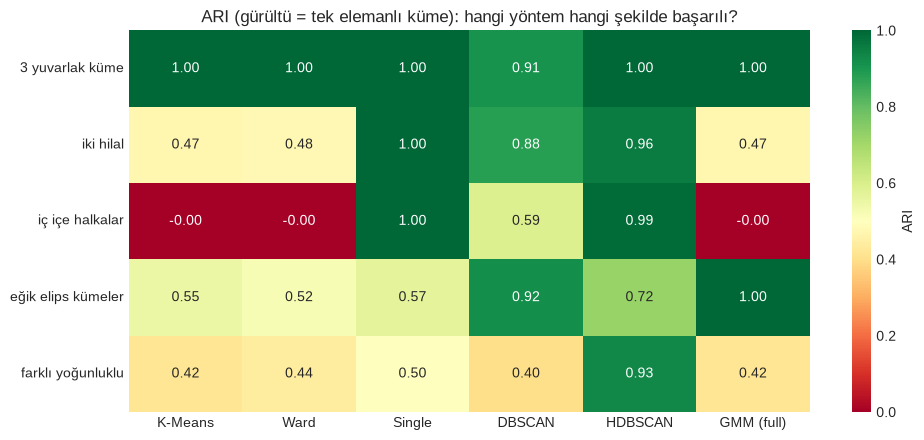

Not: ARI hesabında DBSCAN/HDBSCAN'in gürültü (-1) noktaları tek elemanlı kendi kümesi sayıldı (ari_strict, Adım 10).


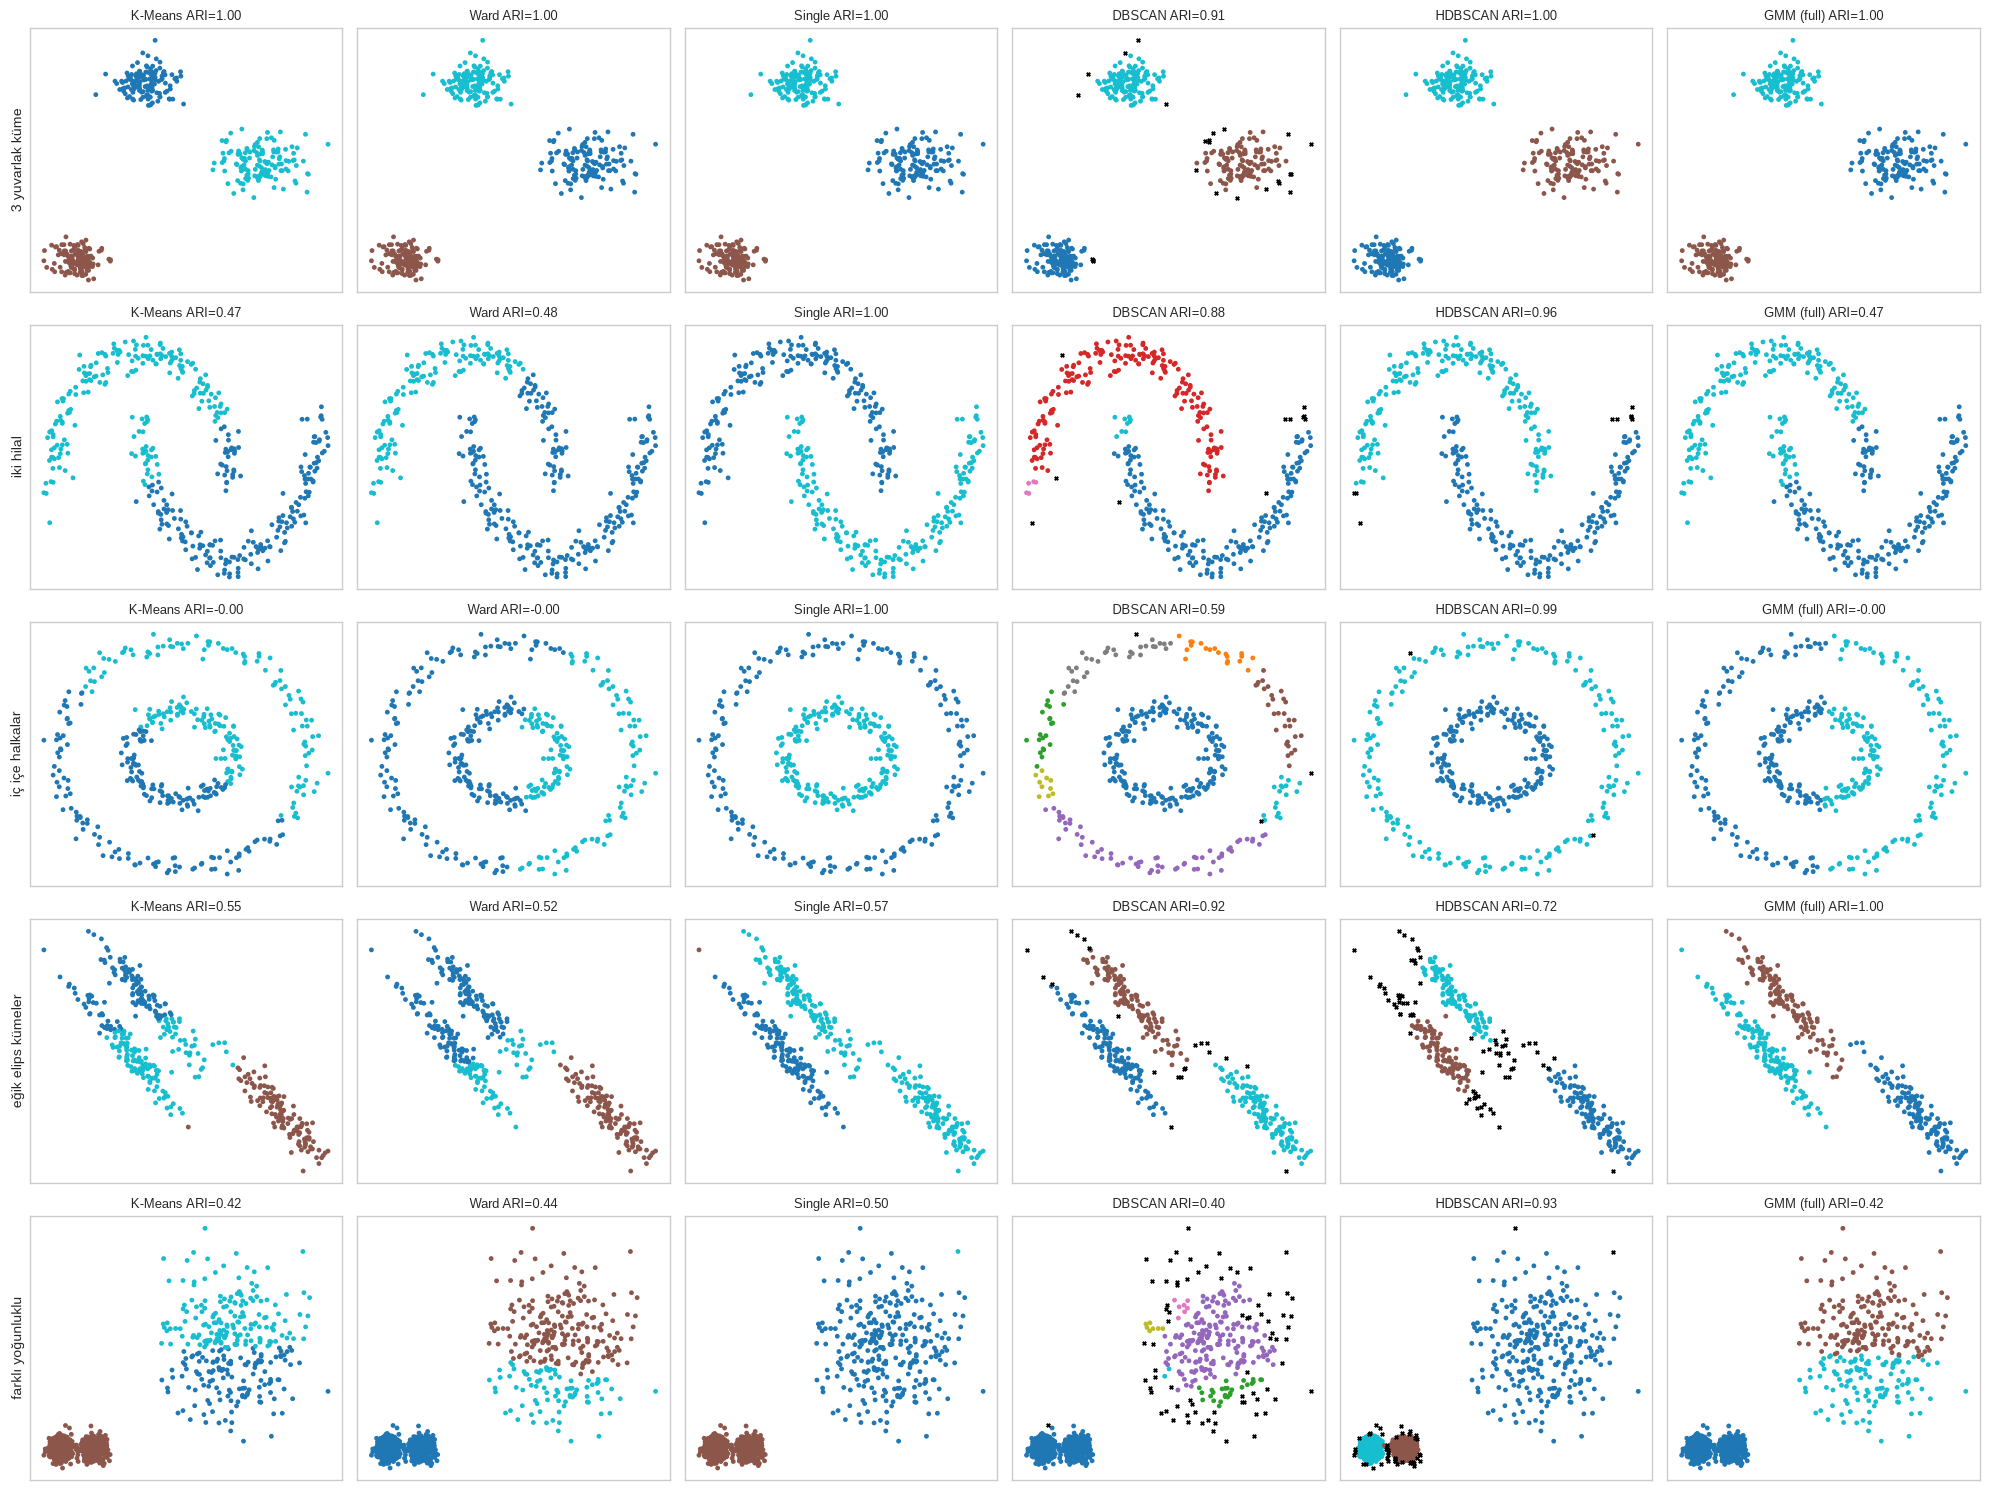

In [32]:
shapes2 = dict(shapes)
shapes2['farklı yoğunluklu'] = (X_var, y_var)

def auto_eps(Xs, k=5, q=90):
    d, _ = NearestNeighbors(n_neighbors=k).fit(Xs).kneighbors(Xs)
    return np.percentile(d[:, -1], q)

method_names = ['K-Means', 'Ward', 'Single', 'DBSCAN', 'HDBSCAN', 'GMM (full)']
results, labels_store = {}, {}
for sname, (Xs, ys) in shapes2.items():
    Xsc = StandardScaler().fit_transform(Xs); k = len(np.unique(ys))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', FutureWarning)           # HDBSCAN `copy` varsayılan değer uyarısı (kütüphane API'si)
        labs = {
            'K-Means': KMeans(k, n_init=10, random_state=42).fit_predict(Xsc),
            'Ward': AgglomerativeClustering(k, linkage='ward').fit_predict(Xsc),
            'Single': AgglomerativeClustering(k, linkage='single').fit_predict(Xsc),
            'DBSCAN': DBSCAN(eps=auto_eps(Xsc), min_samples=5).fit_predict(Xsc),
            'HDBSCAN': HDBSCAN(min_cluster_size=20).fit_predict(Xsc),
            'GMM (full)': GaussianMixture(k, covariance_type='full', n_init=5, random_state=42).fit_predict(Xsc),
        }
    for m, lab in labs.items():
        results[(sname, m)] = ari_strict(ys, lab)
    labels_store[sname] = (Xsc, labs)

ari_all = pd.Series(results).unstack().loc[list(shapes2.keys()), method_names].round(2)
display(ari_all)
winners = {s: ', '.join(ari_all.columns[ari_all.loc[s] >= ari_all.loc[s].max() - 0.02]) for s in ari_all.index}
print('Her şekilde (en yüksek ARI\'ya 0.02 içinde) öne çıkan yöntemler:')
for s, w_ in winners.items():
    print(f'  {s:20s}: {w_}')
print('YORUM: Hiçbir yöntem her şekilde kazanmıyor — K-Means/Ward/GMM kompakt kümelerde, Single/HDBSCAN şekilli kümelerde (otomatik eps ile DBSCAN bu kadar başarılı değil),')
print('GMM(full) eğik elipslerde, HDBSCAN farklı yoğunlukta öne çıkıyor. Doğru yöntem, verinin geometrisine (ve gürültü/olasılık ihtiyacına) göre seçilir.')

plt.figure(figsize=(10, 4.5))
sns.heatmap(ari_all, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, cbar_kws={'label': 'ARI'})
plt.title('ARI (gürültü = tek elemanlı küme): hangi yöntem hangi şekilde başarılı?'); plt.tight_layout(); plt.show()
print('Not: ARI hesabında DBSCAN/HDBSCAN\'in gürültü (-1) noktaları tek elemanlı kendi kümesi sayıldı (ari_strict, Adım 10).')

fig, axes = plt.subplots(len(shapes2), len(method_names), figsize=(20, 15))
for r, (sname, (Xsc, labs)) in enumerate(labels_store.items()):
    for c, m in enumerate(method_names):
        lab = labs[m]
        axes[r, c].scatter(Xsc[lab >= 0, 0], Xsc[lab >= 0, 1], c=lab[lab >= 0], cmap='tab10', s=6)
        axes[r, c].scatter(Xsc[lab == -1, 0], Xsc[lab == -1, 1], c='k', marker='x', s=6)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(f'{m} ARI={results[(sname, m)]:.2f}', fontsize=9)
    axes[r, 0].set_ylabel(sname, fontsize=10)
plt.tight_layout(); plt.show()

In [33]:
# --- İç metrikler yanıltabilir: hilal verisi ---
Xm, ym = labels_store['iki hilal'][0], shapes2['iki hilal'][1]
labs_m = labels_store['iki hilal'][1]
rows = []
for m in ['K-Means', 'DBSCAN', 'GMM (full)']:
    lab = labs_m[m]
    mask = lab >= 0                                    # gürültü etiketini metriğe sokmuyoruz
    if len(set(lab[mask])) < 2:
        continue
    rows.append({'yöntem': m, 'ARI (gerçek etiketle)': adjusted_rand_score(ym, lab),
                 'Silhouette ↑': silhouette_score(Xm[mask], lab[mask]),
                 'Davies-Bouldin ↓': davies_bouldin_score(Xm[mask], lab[mask]),
                 'Calinski-Harabasz ↑': calinski_harabasz_score(Xm[mask], lab[mask])})
rows.append({'yöntem': 'GERÇEK etiketler', 'ARI (gerçek etiketle)': 1.0,
             'Silhouette ↑': silhouette_score(Xm, ym), 'Davies-Bouldin ↓': davies_bouldin_score(Xm, ym),
             'Calinski-Harabasz ↑': calinski_harabasz_score(Xm, ym)})
met = pd.DataFrame(rows).set_index('yöntem').round(3)
display(met)
print('YORUM: Hilal verisinde doğru bölümleme (GERÇEK etiketler / DBSCAN) iç metriklerde, yanlış ama "yuvarlak" bölen')
print('K-Means\'ten daha KÖTÜ puan alabiliyor. İç metrikler yuvarlak/kompakt kümeleri ödüllendirir (§5): şekil karmaşıksa')
print('metrik değil görselleştirme + alan bilgisi karar vermeli. İç metrik ancak benzer varsayımlı yöntemleri kıyaslarken güvenilirdir.')

,ARI (gerçek etiketle),Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
yöntem,,,,
K-Means,0.475,0.492,0.817,542.752
DBSCAN,0.881,0.072,1.752,140.625
GMM (full),0.475,0.492,0.817,542.752
GERÇEK etiketler,1.000,0.377,1.043,331.461


YORUM: Hilal verisinde doğru bölümleme (GERÇEK etiketler / DBSCAN) iç metriklerde, yanlış ama "yuvarlak" bölen
K-Means'ten daha KÖTÜ puan alabiliyor. İç metrikler yuvarlak/kompakt kümeleri ödüllendirir (§5): şekil karmaşıksa
metrik değil görselleştirme + alan bilgisi karar vermeli. İç metrik ancak benzer varsayımlı yöntemleri kıyaslarken güvenilirdir.


# 📊 R Uygulaması

R, bu üç yöntem için Python'dan **daha zengin/standart** araçlar sunuyor: hiyerarşik kümeleme
base R'da hazır (`hclust`) ve GMM için **`mclust`** paketi (Fraley & Raftery) bu alanın
referans uygulaması — kovaryans türleri ve bileşen sayısını **BIC ile otomatik** seçip tek
çağrıda sonuç veriyor. Proje kararı gereği (bkz. [[notebook_style_convention]]) R bölümünü
kısa tutuyoruz: 1 hücre `hclust` + `cutree` (USArrests), 1 hücre `mclust` (faithful).

In [ ]:
%load_ext rpy2.ipython
arrests_for_r = arrests[['Murder', 'Assault', 'UrbanPop', 'Rape']].reset_index()
faithful_for_r = faith.reset_index(drop=True)

In [ ]:
%%R -i arrests_for_r -w 900 -h 600
# base R: hclust (Ward.D2 = scipy'ın Ward'ı ile aynı mantık; "ward.D" farklı bir konvansiyondur)
rownames(arrests_for_r) <- arrests_for_r$State
X <- scale(arrests_for_r[, c("Murder", "Assault", "UrbanPop", "Rape")])
hc <- hclust(dist(X), method = "ward.D2")
groups <- cutree(hc, k = 4)

cat("Küme boyutları:", table(groups), "\n")
cat("Kofenetik korelasyon:", round(cor(dist(X), cophenetic(hc)), 4), "\n")
plot(hc, cex = 0.6, main = "USArrests - Ward.D2 dendrogramı")
rect.hclust(hc, k = 4, border = 2:5)       # k=4 kesimini renkli çerçevelerle göster

In [ ]:
%%R -i faithful_for_r -w 900 -h 500
# install.packages("mclust")  # ilk çalıştırmada gerekiyorsa
library(mclust)

# Mclust: K=1..9 ve 14 kovaryans yapısını (EII, VVV, ...) BIC ile otomatik tarar
fit <- Mclust(faithful_for_r[, c("waiting", "eruptions")])
cat("Seçilen model:", fit$modelName, "| bileşen sayısı:", fit$G, "| BIC:", round(fit$bic, 1), "\n")
print(summary(fit, parameters = TRUE))
plot(fit, what = "classification")

# 🗄️ SQL Uygulaması (DuckDB)

Bu serinin tekrar eden desenini (bkz. [[classical_ml_progress]] "SQL ile Model Inference'ının
Yeniden Üretimi") iki **aydınlatıcı** noktada uyguluyoruz; proje kararı gereği (bkz.
[[notebook_style_convention]]) ikisi de tek hücre:

1. **DBSCAN'in çekirdek noktaları:** "her noktanın $\varepsilon$ içindeki komşu sayısı" sorgusu, SQL'de
   **kendisiyle `CROSS JOIN` + `GROUP BY` + `HAVING COUNT(*) >= minPts`**'dir (haversine formülü SQL'de
   `sin/cos/asin` ile) — ε-sorgusu ile bir kendine-birleştirme (self-join) arasındaki bağı gösterir.
2. **GMM sorumlulukları:** Fit edilmiş GMM'in parametrelerini tabloya koyup 2B Gauss yoğunluğunu
   SQL'de (kapalı formla: 2×2 kovaryansın determinantı ve tersi) hesaplayıp `predict_proba`'yı
   yeniden üretiyoruz.

In [37]:
import duckdb
con = duckdb.connect()

# --- SQL-1: DBSCAN çekirdek noktaları (haversine self-join) ---
pts = pd.DataFrame({'id': np.arange(len(quakes)), 'lat_r': R_rad[:, 0], 'lon_r': R_rad[:, 1]})
con.register('pts', pts)
sql_core = f"""
WITH pairs AS (
    SELECT a.id AS id,
           2 * {EARTH_R} * ASIN(SQRT(
               POWER(SIN((b.lat_r - a.lat_r) / 2), 2) +
               COS(a.lat_r) * COS(b.lat_r) * POWER(SIN((b.lon_r - a.lon_r) / 2), 2)
           )) AS dist_km
    FROM pts a CROSS JOIN pts b
)
SELECT id, COUNT(*) AS n_neighbors
FROM pairs
WHERE dist_km <= {EPS_KM}
GROUP BY id
HAVING COUNT(*) >= {MIN_SAMPLES}
ORDER BY id
"""
core_sql = con.execute(sql_core).df()
core_ids_sql = set(core_sql['id'])
core_ids_sk = set(db.core_sample_indices_)
print(f'SQL çekirdek nokta sayısı: {len(core_ids_sql)} | sklearn core_sample_indices_: {len(core_ids_sk)}')
print('Aynı çekirdek nokta kümesi mi?', core_ids_sql == core_ids_sk)
print('\nYORUM: ε-komşuluk sorgusu SQL\'de bir self-join + COUNT; çekirdek nokta tanımı da HAVING koşulu. DBSCAN\'in')
print('geri kalanı (çekirdekleri zincirleme birleştirme) özyinelemeli bir bağlantılı-bileşen problemidir.')

SQL çekirdek nokta sayısı: 931 | sklearn core_sample_indices_: 931
Aynı çekirdek nokta kümesi mi? True

YORUM: ε-komşuluk sorgusu SQL'de bir self-join + COUNT; çekirdek nokta tanımı da HAVING koşulu. DBSCAN'in
geri kalanı (çekirdekleri zincirleme birleştirme) özyinelemeli bir bağlantılı-bileşen problemidir.


In [38]:
# --- SQL-2: GMM sorumlulukları (2B Gauss, 2x2 kovaryans kapalı formu) ---
K = sk_gmm.n_components
params = pd.DataFrame({
    'comp': np.arange(K), 'w': sk_gmm.weights_,
    'mx': sk_gmm.means_[:, 0], 'my': sk_gmm.means_[:, 1],
    's11': sk_gmm.covariances_[:, 0, 0], 's12': sk_gmm.covariances_[:, 0, 1], 's22': sk_gmm.covariances_[:, 1, 1],
})
data = pd.DataFrame({'id': np.arange(len(X_f)), 'x': X_f[:, 0], 'y': X_f[:, 1]})
con.register('params', params); con.register('data', data)

sql_gmm = """
WITH dens AS (
    SELECT d.id, p.comp,
           p.w * EXP(-0.5 * (
               (p.s22 * POWER(d.x - p.mx, 2) - 2 * p.s12 * (d.x - p.mx) * (d.y - p.my) + p.s11 * POWER(d.y - p.my, 2))
               / (p.s11 * p.s22 - p.s12 * p.s12)
           )) / (2 * PI() * SQRT(p.s11 * p.s22 - p.s12 * p.s12)) AS weighted_pdf
    FROM data d CROSS JOIN params p
)
SELECT id, comp, weighted_pdf / SUM(weighted_pdf) OVER (PARTITION BY id) AS resp
FROM dens
ORDER BY id, comp
"""
resp_sql = con.execute(sql_gmm).df().pivot(index='id', columns='comp', values='resp').to_numpy()
print('SQL sorumlulukları vs sklearn predict_proba, max |fark| =', np.abs(resp_sql - sk_gmm.predict_proba(X_f)).max())
print('YORUM: Yumuşak atama, SQL\'de "ağırlıklı yoğunluk / pencere fonksiyonuyla toplam" kalıbıyla yeniden üretildi —')
print('GMM çıkarımı (inference) tamamen CROSS JOIN + SUM() OVER (PARTITION BY ...) ile ifade edilebiliyor.')

SQL sorumlulukları vs sklearn predict_proba, max |fark| = 9.159339953157541e-16
YORUM: Yumuşak atama, SQL'de "ağırlıklı yoğunluk / pencere fonksiyonuyla toplam" kalıbıyla yeniden üretildi —
GMM çıkarımı (inference) tamamen CROSS JOIN + SUM() OVER (PARTITION BY ...) ile ifade edilebiliyor.


## ✏️ Egzersizler

Hepsi bu notebook'ta tanımlı değişkenlerle ve **hazır modellerle** çözülebilir (sıfırdan kod
yazmak gerekmiyor); her egzersizde kodun altına 1-2 cümlelik yorumunu da yaz.

**E1.** USArrests'te (ölçekli `X_ar`) `AgglomerativeClustering(n_clusters=4, linkage='average')`
ile kümeleme yap. Ward ile bulduğumuz kümelemeyle (`arrests['cluster_ward']`) **ARI**'sini hesapla.
İki kümelemede farklı kümeye düşen eyaletlerden birkaçını yazdır — fark nereden kaynaklanıyor olabilir?

In [39]:
# Kodunu buraya yaz

**E2.** `quakes` verisinde (`R_rad`, `EARTH_R` hazır) `DBSCAN`'i `min_samples=10` ile
$\varepsilon=60$ km ve $\varepsilon=250$ km için ayrı ayrı çalıştır (haversine). Her ikisi için küme
sayısını ve gürültü noktası sayısını yazdır. Sonuçlar Adım 9'daki ısı haritasıyla tutarlı mı?

In [40]:
# Kodunu buraya yaz

**E3.** `faithful` verisine (`X_f`) `GaussianMixture(n_components=3, covariance_type='full')` fit et
ve **BIC** değerini `n_components=2` modeliyle karşılaştır. Hangisi daha iyi? Üçüncü bileşenin
ağırlığına (`weights_`) bakarak neden öyle olduğunu yorumla.

In [41]:
# Kodunu buraya yaz

**E4.** USArrests'te **ölçeklemeden** (`arrests[['Murder','Assault','UrbanPop','Rape']].values`)
Ward ile 4 kümeye ayır. Ölçekli sonuçla (`arrests['cluster_ward']`) ARI'sini hesapla ve ham verideki küme
ortalamalarına bakarak kümelemenin hangi özniteliğe "baskın" olduğunu söyle (Adım 1'i hatırla).

In [42]:
# Kodunu buraya yaz

**E5.** `make_moons(n_samples=400, noise=0.07, random_state=42)` verisinde `DBSCAN(eps=0.2, min_samples=5)`
ve `KMeans(n_clusters=2)` kullan; ikisinin de gerçek etiketlerle **ARI**'sini hesapla ve iki grafiği yan
yana çiz. DBSCAN neden kazanıyor?

In [43]:
# Kodunu buraya yaz

**E6.** `faithful` verisinde `sk_gmm.predict_proba(X_f)` ile her noktanın en yüksek bileşen olasılığını al.
Olasılığı **0.95'ten küçük** ve **0.99'dan küçük** olan nokta sayılarını yazdır. Eşik yükseldikçe "belirsiz"
nokta sayısı neden artıyor? Bu noktaların `waiting`/`eruptions` değerlerine bakıp hangi bölgede yoğunlaştıklarını yorumla.

In [44]:
# Kodunu buraya yaz

## 📚 Kaynaklar

| Kaynak | Bölüm | Notlar |
|---|---|---|
| [Ward (1963) — "Hierarchical Grouping to Optimize an Objective Function", *JASA*](https://www.tandfonline.com/doi/abs/10.1080/01621459.1963.10500845) | Ward linkage | Ward yönteminin orijinal makalesi (küme-içi kareler toplamını minimize eden birleştirme) |
| [SciPy — `scipy.cluster.hierarchy` dokümantasyonu](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html) | Hiyerarşik kümeleme | `linkage`, `dendrogram`, `fcluster`, `cophenet` API'si; Ward yüksekliği konvansiyonu |
| [James, Witten, Hastie, Tibshirani — *An Introduction to Statistical Learning (ISLR2)*, Bölüm 12.4](https://www.statlearning.com/) | Hiyerarşik kümeleme, dendrogram okuma | Ücretsiz kitap; USArrests örneği bu kitabın klasik uygulamasıdır |
| [Hastie, Tibshirani, Friedman — *The Elements of Statistical Learning*, Bölüm 14.3](https://hastie.su.domains/ElemStatLearn/) | Kümeleme (ilerleme düzeyi) | Ücretsiz kitap; linkage'ler, zincirleme etkisi, GMM-EM ilişkisi |
| [Ester, Kriegel, Sander, Xu (1996) — "A Density-Based Algorithm for Discovering Clusters" (KDD)](https://www.aaai.org/Papers/KDD/1996/KDD96-037.pdf) | DBSCAN | DBSCAN'in orijinal makalesi |
| [Schubert, Sander, Ester, Kriegel, Xu (2017) — "DBSCAN Revisited, Revisited" (*ACM TODS*)](https://dl.acm.org/doi/10.1145/3068335) | DBSCAN pratik rehberi | ε/minPts seçimi, sınır noktası belirsizliği ve ne zaman DBSCAN kullanılmamalı |
| [Ankerst, Breunig, Kriegel, Sander (1999) — "OPTICS: Ordering Points To Identify the Clustering Structure"](https://dl.acm.org/doi/10.1145/304181.304187) | OPTICS | Ulaşılabilirlik grafiği ve farklı yoğunluklar |
| [Campello, Moulavi, Sander (2013) — "Density-Based Clustering Based on Hierarchical Density Estimates"](https://link.springer.com/chapter/10.1007/978-3-642-37456-2_14) | HDBSCAN | HDBSCAN'in orijinal makalesi |
| [McInnes — "How HDBSCAN Works"](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html) | HDBSCAN sezgisi | Görsel, adım adım anlatım |
| [Dempster, Laird, Rubin (1977) — "Maximum Likelihood from Incomplete Data via the EM Algorithm", *JRSS B*](https://www.jstor.org/stable/2984875) | EM algoritması | EM'in orijinal makalesi |
| [Bishop — *Pattern Recognition and Machine Learning*, Bölüm 9 (ücretsiz PDF)](https://www.microsoft.com/en-us/research/uploads/prod/2006/01/Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf) | GMM + EM | K-Means ↔ GMM ilişkisinin en net anlatımı |
| [Scrucca, Fop, Murphy, Raftery (2016) — "mclust 5", *The R Journal*](https://journal.r-project.org/archive/2016/RJ-2016-021/index.html) | `mclust` (R) | R'ın referans GMM paketi, BIC ile model seçimi |
| [Davies & Bouldin (1979), *IEEE TPAMI*](https://ieeexplore.ieee.org/document/4766909) | Davies-Bouldin indeksi | İç kümeleme metriği |
| [scikit-learn — Clustering (User Guide)](https://scikit-learn.org/stable/modules/clustering.html) | Tüm kümeleme yöntemleri | Resmi karşılaştırma tablosu ve metrikler |
| [scikit-learn — Gaussian Mixture Models (User Guide)](https://scikit-learn.org/stable/modules/mixture.html) | GMM | Kovaryans türleri, BIC/AIC, `reg_covar` |
| [Azzalini & Bowman (1990) — "A Look at Some Data on the Old Faithful Geyser", *JRSS C*](https://www.jstor.org/stable/2347385) | `faithful` verisi | Veri setinin orijinal makalesi |
| [Rdatasets — USArrests](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/USArrests.html) · [quakes](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/quakes.html) · [faithful](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/faithful.html) | Veri setleri | R `datasets` paketinden birebir CSV aynaları |